
# 6. pan_atlas

**Goal.** Test whether proteins that are well predicted by the models are enriched in external protein/gene atlas groups.

This notebook compares five **individual threshold sets only**:

1. `Pearson >= 0.50`
2. `Pearson >= 0.70`
3. `Cosine >= 0.50`
4. `Cosine >= 0.70`
5. `MSE <= 0.25`

There is **no intersection analysis** in this notebook.

For each atlas group, the notebook reports:

- how many threshold-passing proteins are in the group;
- `% of threshold set`, i.e. how much of the selected model-predicted set belongs to the atlas group;
- `% of atlas group captured`, i.e. how much of that atlas group is well predicted;
- fold enrichment against the tested-protein universe;
- Fisher exact test p-value and Benjamini-Hochberg FDR;
- concise labels for atlas groups that look **well predicted**.



## 1. External resources used

The notebook downloads public annotation resources into `pan_atlas_downloads/` and bundles them into `pan_atlas_resources.zip` for reproducibility.

| Source | What it contributes | Download used in this notebook | Notes |
|---|---|---|---|
| **Human Protein Atlas (HPA)** | Protein classes such as enzymes, transporters, predicted intracellular proteins, plasma proteins, disease-related genes | `https://www.proteinatlas.org/download/proteinatlas.tsv.zip` | Main protein-centric class resource. |
| **HPA subcellular location** | Experimental/predicted subcellular compartments | `https://www.proteinatlas.org/download/subcellular_location.tsv.zip` | Optional; skipped automatically if unavailable. |
| **UniProtKB Human** | Keywords, GO annotations, subcellular notes, UniProt IDs | UniProt REST TSV stream for human proteins | Useful because it is protein-centric and gives many functional keywords. |
| **GOA Human / Gene Ontology annotations** | Biological process, molecular function, cellular component annotations | `https://current.geneontology.org/annotations/goa_human.gaf.gz` | Large and highly overlapping; enrichment statistics are more informative than raw percentages. |
| **Reactome** | Curated pathway gene sets | `https://reactome.org/download/current/ReactomePathways.gmt.zip` | Pathway interpretation of well-predicted proteins. |
| **WikiPathways** | Community-curated pathway gene sets | current Homo sapiens GMT from WikiPathways data archive | Optional; the notebook tries to find the current file automatically. |

The downloaded sources are normalized to one long table:

```text
source, collection, group_name, gene_symbol, uniprot_id, ensembl_id
```

This makes all atlas resources comparable using the same overlap/enrichment functions.


In [1]:

# 2. Setup

from pathlib import Path
import os
import re
import io
import gzip
import json
import zipfile
import shutil
import warnings
import urllib.parse
import urllib.request
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from scipy.stats import fisher_exact
except Exception as e:
    fisher_exact = None
    warnings.warn(f"scipy not available; Fisher exact p-values will be set to NaN. Error: {e}")

pd.set_option("display.max_columns", 120)
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 180)

BASE_DIR = Path.cwd()
DOWNLOAD_DIR = BASE_DIR / "pan_atlas_downloads"
OUTPUT_DIR = BASE_DIR / "pan_atlas_outputs"
PLOTS_DIR = OUTPUT_DIR / "plots"
TABLES_DIR = OUTPUT_DIR / "tables"

for d in [DOWNLOAD_DIR, OUTPUT_DIR, PLOTS_DIR, TABLES_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# Threshold sets requested: individual sets only, no intersections.
THRESHOLD_DEFINITIONS = [
    {"condition": "Pearson >= 0.50", "metric": "pearson", "op": ">=", "value": 0.50},
    {"condition": "Pearson >= 0.70", "metric": "pearson", "op": ">=", "value": 0.70},
    {"condition": "Cosine >= 0.50",  "metric": "cosine",  "op": ">=", "value": 0.50},
    {"condition": "Cosine >= 0.70",  "metric": "cosine",  "op": ">=", "value": 0.70},
    {"condition": "MSE <= 0.25",     "metric": "mse",     "op": "<=", "value": 0.25},
]
condition_order = [x["condition"] for x in THRESHOLD_DEFINITIONS]

# Filters for atlas groups to avoid extremely tiny or uninformative groups.
MIN_GROUP_SIZE_IN_UNIVERSE = 5
MIN_OVERLAP = 3
FDR_CUTOFF = 0.05
FOLD_ENRICHMENT_CUTOFF = 1.5
TOP_N_GROUPS_PER_PLOT = 18

# If a local result table is not auto-detected, put its path here.
# It should contain one row per protein/model/family or already-best row, with columns for a protein/gene id and metrics.
RESULTS_PATH_OVERRIDE = None

# Optional: restrict to a specific model/family before building threshold sets.
# Leave as None to use the best available value per protein for each metric.
MODEL_FAMILY_FILTER = None

print("Output folder:", OUTPUT_DIR.resolve())


Output folder: C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\pan_atlas_outputs


In [2]:

# 3. Small utility functions

def clean_gene_symbol(x):
    if pd.isna(x):
        return np.nan
    x = str(x).strip()
    if not x:
        return np.nan
    # Keep first token for strings like "TP53 P53" only when needed later.
    return x.upper()


def split_multi_value(x, seps=(";", ",", "|")):
    if pd.isna(x):
        return []
    s = str(x).strip()
    if not s:
        return []
    pattern = "|".join(re.escape(sep) for sep in seps)
    vals = [v.strip() for v in re.split(pattern, s) if v.strip()]
    return vals


def normalize_group_name(x):
    if pd.isna(x):
        return np.nan
    x = str(x).strip()
    x = re.sub(r"\s+", " ", x)
    return x if x else np.nan


def first_existing_col(df, candidates, required=True, label="column"):
    lower_to_col = {c.lower(): c for c in df.columns}
    for cand in candidates:
        if cand in df.columns:
            return cand
        if cand.lower() in lower_to_col:
            return lower_to_col[cand.lower()]
    if required:
        raise KeyError(f"Could not find {label}. Tried: {candidates}. Available columns include: {list(df.columns)[:30]}")
    return None


def bh_fdr(pvalues):
    p = np.asarray(pvalues, dtype=float)
    q = np.full_like(p, np.nan, dtype=float)
    valid = np.isfinite(p)
    if valid.sum() == 0:
        return q
    pv = p[valid]
    order = np.argsort(pv)
    ranks = np.arange(1, len(pv) + 1)
    q_sorted = pv[order] * len(pv) / ranks
    q_sorted = np.minimum.accumulate(q_sorted[::-1])[::-1]
    q_valid = np.empty_like(pv)
    q_valid[order] = np.minimum(q_sorted, 1.0)
    q[valid] = q_valid
    return q


def savefig(name, dpi=240):
    path = PLOTS_DIR / name
    plt.savefig(path, dpi=dpi, bbox_inches="tight")
    plt.show()
    print(f"Saved plot: {path}")


def safe_slug(x):
    return re.sub(r"[^A-Za-z0-9]+", "_", str(x)).strip("_").lower()


In [3]:

# 4. Download atlas resources and bundle them into one reproducible zip

RESOURCE_URLS = {
    "hpa_proteinatlas.tsv.zip": "https://www.proteinatlas.org/download/proteinatlas.tsv.zip",
    "hpa_subcellular_location.tsv.zip": "https://www.proteinatlas.org/download/subcellular_location.tsv.zip",
    "goa_human.gaf.gz": "https://current.geneontology.org/annotations/goa_human.gaf.gz",
    "reactome_pathways.gmt.zip": "https://reactome.org/download/current/ReactomePathways.gmt.zip",
}

UNIPROT_HUMAN_URL = (
    "https://rest.uniprot.org/uniprotkb/stream?"
    + urllib.parse.urlencode({
        "compressed": "true",
        "format": "tsv",
        "query": "(organism_id:9606)",
        "fields": "accession,gene_primary,gene_names,protein_name,keyword,go_id,go_p,go_f,go_c,cc_subcellular_location",
    })
)
RESOURCE_URLS["uniprot_human.tsv.gz"] = UNIPROT_HUMAN_URL


def download_file(url, out_path, overwrite=False, timeout=120):
    out_path = Path(out_path)
    if out_path.exists() and out_path.stat().st_size > 0 and not overwrite:
        print(f"Already exists: {out_path.name}")
        return True
    try:
        print(f"Downloading {out_path.name} ...")
        with urllib.request.urlopen(url, timeout=timeout) as r, open(out_path, "wb") as f:
            shutil.copyfileobj(r, f)
        print(f"Downloaded: {out_path} ({out_path.stat().st_size / 1e6:.2f} MB)")
        return True
    except Exception as e:
        print(f"Skipped {out_path.name}: {e}")
        return False


def find_current_wikipathways_human_gmt():
    """Try to discover the latest Homo sapiens GMT file from the WikiPathways directory listing."""
    directories = [
        "https://wikipathways-data.wmcloud.org/current/gmt/",
        "https://data.wikipathways.org/current/gmt/",
    ]
    for base_url in directories:
        try:
            with urllib.request.urlopen(base_url, timeout=30) as r:
                html = r.read().decode("utf-8", errors="ignore")
            matches = re.findall(r'href=["\']([^"\']*Homo_sapiens[^"\']*\.gmt)["\']', html)
            if not matches:
                matches = re.findall(r'(wikipathways-[^\s"\']*gmt-Homo_sapiens\.gmt)', html)
            if matches:
                filename = sorted(set(matches))[-1]
                return urllib.parse.urljoin(base_url, filename)
        except Exception:
            pass
    return None

# Download core resources.
download_status = {}
for fname, url in RESOURCE_URLS.items():
    download_status[fname] = download_file(url, DOWNLOAD_DIR / fname, overwrite=False)

# Optional WikiPathways current human GMT.
wp_url = find_current_wikipathways_human_gmt()
if wp_url:
    download_status["wikipathways_human.gmt"] = download_file(wp_url, DOWNLOAD_DIR / "wikipathways_human.gmt", overwrite=False)
else:
    print("Could not auto-discover current WikiPathways Homo sapiens GMT. WikiPathways will be skipped unless a local file is added.")
    download_status["wikipathways_human.gmt"] = False

# Bundle whatever was successfully downloaded.
zip_path = BASE_DIR / "pan_atlas_resources.zip"
with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as z:
    for f in sorted(DOWNLOAD_DIR.glob("*")):
        if f.is_file() and f.stat().st_size > 0:
            z.write(f, arcname=f.name)

print("\nDownload status:")
for k, v in download_status.items():
    print(f"  {k}: {'OK' if v else 'missing/skipped'}")
print(f"\nResource bundle created: {zip_path.resolve()}")


Already exists: hpa_proteinatlas.tsv.zip
Skipped hpa_subcellular_location.tsv.zip: HTTP Error 404: Not Found
Skipped goa_human.gaf.gz: HTTP Error 403: Forbidden
Already exists: reactome_pathways.gmt.zip
Already exists: uniprot_human.tsv.gz
Already exists: wikipathways_human.gmt

Download status:
  hpa_proteinatlas.tsv.zip: OK
  hpa_subcellular_location.tsv.zip: missing/skipped
  goa_human.gaf.gz: missing/skipped
  reactome_pathways.gmt.zip: OK
  uniprot_human.tsv.gz: OK
  wikipathways_human.gmt: OK

Resource bundle created: C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\pan_atlas_resources.zip



## 5. Load model output table

The notebook tries to auto-detect a model result CSV/TSV/Parquet from nearby folders. If detection fails or selects the wrong file, set `RESULTS_PATH_OVERRIDE` in Section 2.

Expected content:

- one protein/gene identifier column, such as `protein`, `Gene`, `gene`, `target`, `protein_name`, `protein_key`, or `Uniprot`;
- metric columns for Pearson, cosine similarity, and MSE.

If there are multiple rows per protein/model, the notebook keeps the **best metric value per protein** for each metric:

- max Pearson;
- max cosine;
- min MSE.


In [4]:
# 5. Load result table and construct one best-metric row per protein
#
# Corrected robust loader for 6. pan_atlas.
# This cell replaces the old pick_result_table() / RESULTS_PATH_OVERRIDE logic.
#
# It creates:
#   perf
#   best_metrics
#   threshold_membership
#   threshold_summary
#   condition_order

from pathlib import Path
import re
import numpy as np
import pandas as pd


# ---------------------------------------------------------------------
# Recommended paths from your detected files
# ---------------------------------------------------------------------

DEFAULT_RESULT_PATHS = [
    r"C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\atlas_outputs\atlas_performance_standardized.csv",
    r"C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\comparison_outputs\all_model_results_summary.csv",
    r"C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\output\best_model_per_protein_all_metrics.csv",
]

# If PERFORMANCE_TABLE_PATHS was already set in Section 2, keep it.
# Otherwise, use the first existing recommended file.
if "PERFORMANCE_TABLE_PATHS" not in globals() or PERFORMANCE_TABLE_PATHS is None:
    PERFORMANCE_TABLE_PATHS = []

if not PERFORMANCE_TABLE_PATHS:
    for candidate_path in DEFAULT_RESULT_PATHS:
        if Path(candidate_path).exists():
            PERFORMANCE_TABLE_PATHS = [candidate_path]
            print(f"Using detected default result file:\n  {candidate_path}")
            break

if not PERFORMANCE_TABLE_PATHS:
    raise FileNotFoundError(
        "No default result file was found. Set PERFORMANCE_TABLE_PATHS manually in Section 2, for example:\n\n"
        'PERFORMANCE_TABLE_PATHS = [r"C:\\Users\\hp\\Desktop\\CPPR\\Cancer-Protein-RNA-research\\04.5 ccle comparison\\atlas_outputs\\atlas_performance_standardized.csv"]'
    )


# ---------------------------------------------------------------------
# Directory compatibility
# ---------------------------------------------------------------------

if "BASE_DIR" not in globals():
    BASE_DIR = Path(".").resolve()
else:
    BASE_DIR = Path(BASE_DIR)

if "OUTPUT_DIR" not in globals():
    OUTPUT_DIR = BASE_DIR / "pan_atlas_outputs"
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
else:
    OUTPUT_DIR = Path(OUTPUT_DIR)
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if "TABLES_DIR" not in globals():
    TABLES_DIR = OUTPUT_DIR / "tables"
    TABLES_DIR.mkdir(parents=True, exist_ok=True)
else:
    TABLES_DIR = Path(TABLES_DIR)
    TABLES_DIR.mkdir(parents=True, exist_ok=True)

if "MODEL_FAMILY_FILTER" not in globals():
    MODEL_FAMILY_FILTER = None

if "COLUMN_OVERRIDES" not in globals():
    COLUMN_OVERRIDES = {
        "protein": None,
        "method": None,
        "pearson": None,
        "cosine": None,
        "mse": None,
    }


# ---------------------------------------------------------------------
# Column aliases
# ---------------------------------------------------------------------

PROTEIN_ALIASES = [
    "protein_key",
    "protein_raw",
    "protein",
    "Protein",
    "Gene",
    "gene",
    "target",
    "target_gene",
    "gene_symbol",
    "symbol",
    "uniprot",
    "Uniprot",
    "UniProt",
    "ensembl",
    "Ensembl",
    "protein_name",
    "target_name",
]

METHOD_ALIASES = [
    "method",
    "model",
    "family",
    "model_family",
    "source",
    "approach",
    "predictor",
]

METRIC_ALIASES = {
    "pearson": [
        "pearson",
        "test_pearson",
        "pearson_corr",
        "test_corr",
        "correlation",
        "corr",
        "r",
        "test_r",
    ],
    "cosine": [
        "cosine",
        "cosine_similarity",
        "test_cosine",
        "test_cosine_similarity",
        "cos_sim",
        "cosine_sim",
    ],
    "mse": [
        "mse",
        "test_mse",
        "mean_squared_error",
        "test_mean_squared_error",
        "MSE",
    ],
}


# ---------------------------------------------------------------------
# Helper functions
# ---------------------------------------------------------------------

def read_table(path, nrows=None):
    path = Path(path)

    if not path.exists():
        raise FileNotFoundError(f"File does not exist: {path}")

    suffix = path.suffix.lower()

    if suffix == ".parquet":
        df = pd.read_parquet(path)
        return df.head(nrows) if nrows is not None else df

    if suffix in [".tsv", ".txt"]:
        return pd.read_csv(path, sep="\t", nrows=nrows)

    return pd.read_csv(path, nrows=nrows)


def normalize_colname(x):
    return re.sub(r"[^a-z0-9]+", "", str(x).lower())


def choose_column(columns, aliases, override=None, required=False, label="column"):
    columns = list(columns)

    if override is not None:
        if override in columns:
            return override
        raise ValueError(
            f"Override for {label} was set to {override!r}, but it was not found. "
            f"Available columns include: {columns[:80]}"
        )

    direct = {str(c).lower(): c for c in columns}
    normalized = {normalize_colname(c): c for c in columns}

    for alias in aliases:
        if str(alias).lower() in direct:
            return direct[str(alias).lower()]

    for alias in aliases:
        key = normalize_colname(alias)
        if key in normalized:
            return normalized[key]

    for alias in aliases:
        alias_norm = normalize_colname(alias)
        for col in columns:
            col_norm = normalize_colname(col)
            if alias_norm and alias_norm in col_norm:
                return col

    if required:
        raise ValueError(
            f"Could not detect required {label}. "
            f"Available columns include: {columns[:80]}"
        )

    return None


def clean_identifier_series(s):
    out = s.astype("string").str.strip()

    out = out.str.split(";").str[0]
    out = out.str.split(",").str[0]
    out = out.str.split("|").str[0]
    out = out.str.replace(r"\.\d+$", "", regex=True)
    out = out.str.strip()

    out = out.replace({"": pd.NA, "nan": pd.NA, "None": pd.NA})
    return out


def clean_gene_symbol(x):
    if pd.isna(x):
        return pd.NA

    x = str(x).strip()
    if not x:
        return pd.NA

    x = x.split(";")[0].split(",")[0].split("|")[0].strip()
    x = re.sub(r"\.\d+$", "", x)

    return x.upper()


def standardize_performance_table(raw, source_name="in_memory"):
    raw = raw.copy()

    protein_col = choose_column(
        raw.columns,
        PROTEIN_ALIASES,
        override=COLUMN_OVERRIDES.get("protein"),
        required=True,
        label="protein column",
    )

    method_col = choose_column(
        raw.columns,
        METHOD_ALIASES,
        override=COLUMN_OVERRIDES.get("method"),
        required=False,
        label="method column",
    )

    metric_cols = {}
    for metric, aliases in METRIC_ALIASES.items():
        metric_cols[metric] = choose_column(
            raw.columns,
            aliases,
            override=COLUMN_OVERRIDES.get(metric),
            required=False,
            label=f"{metric} metric column",
        )

    if all(v is None for v in metric_cols.values()):
        raise ValueError(
            f"No Pearson/cosine/MSE columns detected in {source_name}. "
            f"Columns were: {list(raw.columns)[:80]}"
        )

    out = pd.DataFrame({
        "protein_raw": raw[protein_col].astype("string"),
        "protein_key": clean_identifier_series(raw[protein_col]),
        "source_file": source_name,
        "source_row": np.arange(len(raw)),
    })

    if method_col is not None:
        out["method"] = raw[method_col].astype("string")
    else:
        out["method"] = pd.Series(["unknown"] * len(raw), dtype="string")

    for metric, col in metric_cols.items():
        if col is not None:
            out[metric] = pd.to_numeric(raw[col], errors="coerce")
        else:
            out[metric] = np.nan

    out = out.dropna(subset=["protein_key"]).drop_duplicates()
    out["gene_symbol"] = out["protein_key"].map(clean_gene_symbol)

    detected = {
        "protein": protein_col,
        "method": method_col,
        **metric_cols,
    }

    print(f"\nLoaded {source_name}")
    print(f"  Raw shape: {raw.shape[0]:,} rows x {raw.shape[1]:,} columns")
    print(f"  Standardized shape: {out.shape[0]:,} rows x {out.shape[1]:,} columns")
    print(f"  Detected columns: {detected}")

    return out, detected


# ---------------------------------------------------------------------
# Load and standardize result table(s)
# ---------------------------------------------------------------------

raw_tables = []

print("Loading performance table(s):")
for path in PERFORMANCE_TABLE_PATHS:
    path = Path(path)
    print(" -", path)
    raw_tables.append((str(path), read_table(path)))

standardized_frames = []
detected_columns = []

for source_name, raw in raw_tables:
    std, detected = standardize_performance_table(raw, source_name=source_name)
    standardized_frames.append(std)
    detected_columns.append({"source": source_name, **detected})

perf = (
    pd.concat(standardized_frames, ignore_index=True)
    .drop_duplicates()
    .reset_index(drop=True)
)

# Optional method/model filtering.
if MODEL_FAMILY_FILTER is not None:
    mask = perf["method"].astype(str).str.contains(
        str(MODEL_FAMILY_FILTER),
        case=False,
        na=False,
    )

    if mask.sum() == 0:
        print(f"\nMODEL_FAMILY_FILTER={MODEL_FAMILY_FILTER!r} matched 0 rows. Keeping all rows.")
    else:
        perf = perf.loc[mask].copy()
        print(f"\nAfter MODEL_FAMILY_FILTER={MODEL_FAMILY_FILTER}: {perf.shape[0]:,} rows")

print("\nCombined standardized performance table")
print("=" * 48)
print(f"Rows: {perf.shape[0]:,}")
print(f"Unique proteins: {perf['protein_key'].nunique():,}")
print(f"Rows with Pearson: {perf['pearson'].notna().sum():,}")
print(f"Rows with cosine:  {perf['cosine'].notna().sum():,}")
print(f"Rows with MSE:     {perf['mse'].notna().sum():,}")

display(pd.DataFrame(detected_columns))
display(perf.head())

perf.to_csv(OUTPUT_DIR / "atlas_performance_standardized.csv", index=False)


# ---------------------------------------------------------------------
# Best metric per protein
# ---------------------------------------------------------------------

best_metrics = (
    perf.groupby(["protein_key", "gene_symbol"], dropna=False)
    .agg(
        pearson=("pearson", "max"),
        cosine=("cosine", "max"),
        mse=("mse", "min"),
        n_rows=("protein_key", "size"),
        methods=("method", lambda x: "; ".join(sorted(set(x.dropna().astype(str)))[:8])),
    )
    .reset_index()
)

print("\nBest-per-protein metrics")
print("=" * 48)
print(f"Proteins: {best_metrics.shape[0]:,}")
print(f"Pearson available: {best_metrics['pearson'].notna().sum():,}")
print(f"Cosine available:  {best_metrics['cosine'].notna().sum():,}")
print(f"MSE available:     {best_metrics['mse'].notna().sum():,}")

display(best_metrics.head())

best_metrics.to_csv(TABLES_DIR / "best_metrics_per_protein.csv", index=False)


# ---------------------------------------------------------------------
# Build the five individual threshold sets
# ---------------------------------------------------------------------

threshold_definitions = {
    "Pearson >= 0.50": lambda df: df["pearson"] >= 0.50,
    "Pearson >= 0.70": lambda df: df["pearson"] >= 0.70,
    "Cosine >= 0.50": lambda df: df["cosine"] >= 0.50,
    "Cosine >= 0.70": lambda df: df["cosine"] >= 0.70,
    "MSE <= 0.25": lambda df: df["mse"] <= 0.25,
}

condition_order = list(threshold_definitions.keys())

membership_rows = []

for condition, rule in threshold_definitions.items():
    mask = rule(best_metrics).fillna(False)

    temp = best_metrics.loc[
        mask,
        ["protein_key", "gene_symbol", "pearson", "cosine", "mse", "n_rows", "methods"]
    ].copy()

    temp["condition"] = condition
    membership_rows.append(temp)

threshold_membership = (
    pd.concat(membership_rows, ignore_index=True)
    if membership_rows
    else pd.DataFrame()
)

threshold_summary = (
    threshold_membership
    .groupby("condition", observed=False)
    .agg(
        n_proteins=("protein_key", "nunique"),
        median_pearson=("pearson", "median"),
        median_cosine=("cosine", "median"),
        median_mse=("mse", "median"),
    )
    .reindex(condition_order)
    .reset_index()
)

print("\nThreshold-set sizes")
print("=" * 48)

for row in threshold_summary.itertuples(index=False):
    n = 0 if pd.isna(row.n_proteins) else int(row.n_proteins)
    med_p = "NA" if pd.isna(row.median_pearson) else f"{row.median_pearson:.3f}"
    med_c = "NA" if pd.isna(row.median_cosine) else f"{row.median_cosine:.3f}"
    med_m = "NA" if pd.isna(row.median_mse) else f"{row.median_mse:.4f}"

    print(
        f"{row.condition:<16} | "
        f"{n:>5,} proteins | "
        f"median Pearson={med_p} | "
        f"median cosine={med_c} | "
        f"median MSE={med_m}"
    )

display(threshold_summary)

threshold_membership.to_csv(TABLES_DIR / "threshold_membership_individual_sets.csv", index=False)
threshold_summary.to_csv(TABLES_DIR / "threshold_summary_individual_sets.csv", index=False)

Using detected default result file:
  C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\atlas_outputs\atlas_performance_standardized.csv
Loading performance table(s):
 - C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\atlas_outputs\atlas_performance_standardized.csv

Loaded C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\atlas_outputs\atlas_performance_standardized.csv
  Raw shape: 51,290 rows x 8 columns
  Standardized shape: 51,290 rows x 9 columns
  Detected columns: {'protein': 'protein_key', 'method': 'method', 'pearson': 'pearson', 'cosine': 'cosine', 'mse': 'mse'}

Combined standardized performance table
Rows: 51,290
Unique proteins: 5,113
Rows with Pearson: 50,217
Rows with cosine:  51,290
Rows with MSE:     51,290


,source,protein,method,pearson,cosine,mse
0,C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\atlas_output...,protein_key,method,pearson,cosine,mse


,protein_raw,protein_key,source_file,source_row,method,pearson,cosine,mse,gene_symbol
0,A2M,A2M,C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\atlas_output...,0,xgb,0.469012,0.554128,0.760331,A2M
1,A2M,A2M,C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\atlas_output...,1,xgb,0.477427,0.558124,0.753375,A2M
2,A2M,A2M,C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\atlas_output...,2,xgb,0.466232,0.560768,0.751074,A2M
3,A2M,A2M,C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\atlas_output...,3,xgb,0.451791,0.539072,0.778497,A2M
4,A2M,A2M,C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\atlas_output...,4,xgb,0.469012,0.554128,0.760331,A2M



Best-per-protein metrics
Proteins: 5,113
Pearson available: 5,113
Cosine available:  5,113
MSE available:     5,113


,protein_key,gene_symbol,pearson,cosine,mse,n_rows,methods
0,A2M,A2M,0.511406,0.573536,0.733483,15,enet; xgb
1,AAAS,AAAS,0.637295,0.646450,0.102694,15,enet; xgb
2,AACS,AACS,0.675858,0.668078,0.357902,15,enet; xgb
3,AAGAB,AAGAB,0.475606,0.465451,0.450723,15,enet; xgb
4,AAK1,AAK1,0.730509,0.735883,0.261418,15,enet; xgb



Threshold-set sizes
Pearson >= 0.50  | 3,621 proteins | median Pearson=0.662 | median cosine=0.663 | median MSE=0.2732
Pearson >= 0.70  | 1,418 proteins | median Pearson=0.779 | median cosine=0.778 | median MSE=0.3596
Cosine >= 0.50   | 3,695 proteins | median Pearson=0.658 | median cosine=0.660 | median MSE=0.2717
Cosine >= 0.70   | 1,427 proteins | median Pearson=0.779 | median cosine=0.778 | median MSE=0.3589
MSE <= 0.25      | 2,574 proteins | median Pearson=0.542 | median cosine=0.545 | median MSE=0.1834


,condition,n_proteins,median_pearson,median_cosine,median_mse
0,Pearson >= 0.50,3621,0.661914,0.663230,0.273204
1,Pearson >= 0.70,1418,0.779354,0.778456,0.359579
2,Cosine >= 0.50,3695,0.657761,0.659733,0.271652
3,Cosine >= 0.70,1427,0.778787,0.777829,0.358946
4,MSE <= 0.25,2574,0.541582,0.544820,0.183394


In [5]:

# 6. Build the five individual threshold sets

threshold_membership_rows = []
threshold_summary_rows = []

for spec in THRESHOLD_DEFINITIONS:
    cond = spec["condition"]
    metric = spec["metric"]
    op = spec["op"]
    val = spec["value"]
    if op == ">=":
        passed = best_metrics[metric] >= val
    elif op == "<=":
        passed = best_metrics[metric] <= val
    else:
        raise ValueError(op)
    subset = best_metrics.loc[passed.fillna(False)].copy()
    threshold_summary_rows.append({
        "condition": cond,
        "metric": metric,
        "operator": op,
        "threshold": val,
        "n_proteins": subset["protein_key"].nunique(),
        "pct_of_universe": 100 * subset["protein_key"].nunique() / best_metrics["protein_key"].nunique(),
    })
    for r in subset[["protein_key", "gene_symbol", "pearson", "cosine", "mse"]].itertuples(index=False):
        threshold_membership_rows.append({
            "condition": cond,
            "protein_key": r.protein_key,
            "gene_symbol": r.gene_symbol,
            "pearson": r.pearson,
            "cosine": r.cosine,
            "mse": r.mse,
        })

threshold_summary = pd.DataFrame(threshold_summary_rows)
membership = pd.DataFrame(threshold_membership_rows)

print("Threshold sets:")
for row in threshold_summary.itertuples(index=False):
    print(f"  {row.condition}: {int(row.n_proteins):,} proteins ({row.pct_of_universe:.1f}% of tested universe)")

threshold_summary.to_csv(TABLES_DIR / "threshold_set_summary.csv", index=False)
membership.to_csv(TABLES_DIR / "threshold_set_membership_long.csv", index=False)

display(threshold_summary)


Threshold sets:
  Pearson >= 0.50: 3,621 proteins (70.8% of tested universe)
  Pearson >= 0.70: 1,418 proteins (27.7% of tested universe)
  Cosine >= 0.50: 3,695 proteins (72.3% of tested universe)
  Cosine >= 0.70: 1,427 proteins (27.9% of tested universe)
  MSE <= 0.25: 2,574 proteins (50.3% of tested universe)


,condition,metric,operator,threshold,n_proteins,pct_of_universe
0,Pearson >= 0.50,pearson,>=,0.50,3621,70.819480
1,Pearson >= 0.70,pearson,>=,0.70,1418,27.733229
2,Cosine >= 0.50,cosine,>=,0.50,3695,72.266771
3,Cosine >= 0.70,cosine,>=,0.70,1427,27.909251
4,MSE <= 0.25,mse,<=,0.25,2574,50.342265


In [6]:

# 7. Parse atlas resources into one normalized group-membership table

atlas_frames = []


def add_atlas_frame(df, source, collection):
    expected = ["source", "collection", "group_name", "gene_symbol", "uniprot_id", "ensembl_id"]
    out = df.copy()
    out["source"] = source
    out["collection"] = collection
    for col in expected:
        if col not in out.columns:
            out[col] = np.nan
    out = out[expected]
    out["group_name"] = out["group_name"].map(normalize_group_name)
    out["gene_symbol"] = out["gene_symbol"].map(clean_gene_symbol)
    out["uniprot_id"] = out["uniprot_id"].astype(str).replace({"nan": np.nan, "None": np.nan})
    out["ensembl_id"] = out["ensembl_id"].astype(str).replace({"nan": np.nan, "None": np.nan})
    out = out.dropna(subset=["group_name"])
    out = out.loc[out["gene_symbol"].notna() | out["uniprot_id"].notna() | out["ensembl_id"].notna()]
    out = out.drop_duplicates()
    atlas_frames.append(out)
    print(f"Added {source} / {collection}: {out.shape[0]:,} rows, {out['group_name'].nunique():,} groups")


def parse_hpa_proteinatlas(path):
    if not Path(path).exists():
        return
    with zipfile.ZipFile(path) as z:
        name = z.namelist()[0]
        hpa = pd.read_csv(z.open(name), sep="\t")
    gene_col = first_existing_col(hpa, ["Gene", "gene"], required=True)
    ensembl_col = first_existing_col(hpa, ["Ensembl", "ensembl"], required=False)
    uniprot_col = first_existing_col(hpa, ["Uniprot", "UniProt", "uniprot"], required=False)
    class_col = first_existing_col(hpa, ["Protein class", "protein_class"], required=False)
    if class_col:
        rows = []
        for row in hpa[[gene_col] + ([ensembl_col] if ensembl_col else []) + ([uniprot_col] if uniprot_col else []) + [class_col]].itertuples(index=False):
            d = row._asdict() if hasattr(row, "_asdict") else None
        for _, r in hpa.iterrows():
            gene = r.get(gene_col)
            ens = r.get(ensembl_col) if ensembl_col else np.nan
            uni = r.get(uniprot_col) if uniprot_col else np.nan
            for cls in split_multi_value(r.get(class_col), seps=(";", ",")):
                rows.append({"gene_symbol": gene, "ensembl_id": ens, "uniprot_id": uni, "group_name": cls})
        add_atlas_frame(pd.DataFrame(rows), "HPA", "protein_class")


def parse_hpa_subcellular(path):
    if not Path(path).exists():
        return
    try:
        with zipfile.ZipFile(path) as z:
            name = z.namelist()[0]
            sub = pd.read_csv(z.open(name), sep="\t")
    except Exception as e:
        print(f"Could not read HPA subcellular file: {e}")
        return
    gene_col = first_existing_col(sub, ["Gene", "gene"], required=False)
    ensembl_col = first_existing_col(sub, ["Ensembl", "ensembl"], required=False)
    loc_cols = [c for c in sub.columns if any(k in c.lower() for k in ["location", "main location", "additional location", "extracellular"])]
    if not gene_col or not loc_cols:
        print("HPA subcellular file found but could not identify gene/location columns.")
        return
    rows = []
    for _, r in sub.iterrows():
        gene = r.get(gene_col)
        ens = r.get(ensembl_col) if ensembl_col else np.nan
        for c in loc_cols:
            for loc in split_multi_value(r.get(c), seps=(";", ",")):
                rows.append({"gene_symbol": gene, "ensembl_id": ens, "group_name": loc})
    if rows:
        add_atlas_frame(pd.DataFrame(rows), "HPA", "subcellular_location")


def parse_uniprot(path):
    if not Path(path).exists():
        return
    try:
        with gzip.open(path, "rt") as f:
            uni = pd.read_csv(f, sep="\t")
    except OSError:
        uni = pd.read_csv(path, sep="\t")
    acc_col = first_existing_col(uni, ["Entry", "accession", "Accession"], required=False)
    gene_col = first_existing_col(uni, ["Gene Names (primary)", "Gene Names", "Gene Names primary", "gene_primary"], required=False)
    rows = []
    for _, r in uni.iterrows():
        acc = r.get(acc_col) if acc_col else np.nan
        gene_raw = r.get(gene_col) if gene_col else np.nan
        gene = str(gene_raw).split()[0] if pd.notna(gene_raw) and str(gene_raw).strip() else np.nan
        # Keywords
        for col in [c for c in uni.columns if "keyword" in c.lower()]:
            for v in split_multi_value(r.get(col), seps=(";", ",")):
                rows.append({"gene_symbol": gene, "uniprot_id": acc, "group_name": v})
        # GO term columns and subcellular location note. Keep terms concise.
        for col in [c for c in uni.columns if c.lower().startswith("go") or "subcellular" in c.lower()]:
            if "id" in col.lower():
                continue
            for v in split_multi_value(r.get(col), seps=(";",)):
                v = re.sub(r"\s*\[GO:\d+\]", "", v).strip()
                v = re.sub(r"SUBCELLULAR LOCATION:\s*", "", v, flags=re.I)
                if len(v) <= 120:
                    rows.append({"gene_symbol": gene, "uniprot_id": acc, "group_name": v})
    if rows:
        add_atlas_frame(pd.DataFrame(rows), "UniProtKB", "keywords_go_subcellular")


def parse_goa_gaf(path):
    if not Path(path).exists():
        return
    cols = [
        "DB", "DB_Object_ID", "DB_Object_Symbol", "Qualifier", "GO_ID", "DB_Reference", "Evidence_Code",
        "With_From", "Aspect", "DB_Object_Name", "DB_Object_Synonym", "DB_Object_Type", "Taxon", "Date",
        "Assigned_By", "Annotation_Extension", "Gene_Product_Form_ID"
    ]
    rows = []
    # GAF has no term names, only GO IDs. Use GO IDs as groups unless ontology names are added later.
    with gzip.open(path, "rt", errors="ignore") as f:
        goa = pd.read_csv(f, sep="\t", comment="!", names=cols, low_memory=False)
    goa = goa.loc[goa["DB_Object_Symbol"].notna() & goa["GO_ID"].notna()].copy()
    aspect_map = {"P": "biological_process", "F": "molecular_function", "C": "cellular_component"}
    goa["group_name"] = goa["Aspect"].map(aspect_map).fillna("GO") + ": " + goa["GO_ID"].astype(str)
    out = goa.rename(columns={"DB_Object_Symbol": "gene_symbol", "DB_Object_ID": "uniprot_id"})[["gene_symbol", "uniprot_id", "group_name"]]
    add_atlas_frame(out, "GOA", "go_annotations")


def read_gmt_fileobj(fileobj, source, collection, species_filter=None):
    rows = []
    content = fileobj.read()
    if isinstance(content, bytes):
        content = content.decode("utf-8", errors="ignore")
    for line in content.splitlines():
        parts = line.rstrip("\n").split("\t")
        if len(parts) < 3:
            continue
        group = parts[0]
        desc = parts[1]
        genes = parts[2:]
        if species_filter and species_filter.lower() not in (group + " " + desc).lower():
            # Reactome GMT often contains all species; pathway names may include species in the second field.
            pass
        for g in genes:
            if g and not g.startswith("http"):
                rows.append({"gene_symbol": g, "group_name": group})
    if rows:
        add_atlas_frame(pd.DataFrame(rows), source, collection)


def parse_reactome_gmt_zip(path):
    if not Path(path).exists():
        return
    try:
        with zipfile.ZipFile(path) as z:
            names = [n for n in z.namelist() if n.endswith(".gmt")]
            if not names:
                print("Reactome zip has no GMT file.")
                return
            # Prefer a human-specific file if present.
            name = sorted(names, key=lambda x: ("human" not in x.lower(), len(x)))[0]
            with z.open(name) as f:
                read_gmt_fileobj(f, "Reactome", "pathways")
    except Exception as e:
        print(f"Could not parse Reactome GMT zip: {e}")


def parse_wikipathways_gmt(path):
    if not Path(path).exists():
        return
    try:
        with open(path, "rb") as f:
            read_gmt_fileobj(f, "WikiPathways", "pathways")
    except Exception as e:
        print(f"Could not parse WikiPathways GMT: {e}")

parse_hpa_proteinatlas(DOWNLOAD_DIR / "hpa_proteinatlas.tsv.zip")
parse_hpa_subcellular(DOWNLOAD_DIR / "hpa_subcellular_location.tsv.zip")
parse_uniprot(DOWNLOAD_DIR / "uniprot_human.tsv.gz")
parse_goa_gaf(DOWNLOAD_DIR / "goa_human.gaf.gz")
parse_reactome_gmt_zip(DOWNLOAD_DIR / "reactome_pathways.gmt.zip")
parse_wikipathways_gmt(DOWNLOAD_DIR / "wikipathways_human.gmt")

if not atlas_frames:
    raise RuntimeError("No atlas resources parsed. Check downloads in pan_atlas_downloads/.")

atlas_long = pd.concat(atlas_frames, ignore_index=True).drop_duplicates()
atlas_long["group_id"] = atlas_long["source"] + " | " + atlas_long["collection"] + " | " + atlas_long["group_name"]
atlas_long.to_csv(TABLES_DIR / "pan_atlas_long_group_membership.csv", index=False)

print("\nCombined atlas table:", atlas_long.shape)
print("Sources:")
display(atlas_long.groupby(["source", "collection"]).agg(n_rows=("group_id", "size"), n_groups=("group_id", "nunique"), n_genes=("gene_symbol", "nunique")).reset_index())


Added HPA / protein_class: 55,572 rows, 26 groups


C:\Users\hp\AppData\Local\Temp\ipykernel_43548\1384956316.py:18: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  out["ensembl_id"] = out["ensembl_id"].astype(str).replace({"nan": np.nan, "None": np.nan})


Added UniProtKB / keywords_go_subcellular: 1,559,398 rows, 14,139 groups


C:\Users\hp\AppData\Local\Temp\ipykernel_43548\1384956316.py:17: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  out["uniprot_id"] = out["uniprot_id"].astype(str).replace({"nan": np.nan, "None": np.nan})
C:\Users\hp\AppData\Local\Temp\ipykernel_43548\1384956316.py:18: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  out["ensembl_id"] = out["ensembl_id"].astype(str).replace({"nan": np.nan, "None": np.nan})


Added Reactome / pathways: 140,633 rows, 2,855 groups


C:\Users\hp\AppData\Local\Temp\ipykernel_43548\1384956316.py:17: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  out["uniprot_id"] = out["uniprot_id"].astype(str).replace({"nan": np.nan, "None": np.nan})
C:\Users\hp\AppData\Local\Temp\ipykernel_43548\1384956316.py:18: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  out["ensembl_id"] = out["ensembl_id"].astype(str).replace({"nan": np.nan, "None": np.nan})


Added WikiPathways / pathways: 40,104 rows, 985 groups

Combined atlas table: (1795707, 7)
Sources:


,source,collection,n_rows,n_groups,n_genes
0,HPA,protein_class,55572,26,20151
1,Reactome,pathways,140633,2855,11955
2,UniProtKB,keywords_go_subcellular,1559398,14139,24224
3,WikiPathways,pathways,40104,985,9015


In [7]:

# 8. Match atlas groups to the model-tested universe

universe = best_metrics[["protein_key", "gene_symbol"]].drop_duplicates().copy()
universe["gene_symbol"] = universe["gene_symbol"].map(clean_gene_symbol)
universe_genes = set(universe["gene_symbol"].dropna())

atlas_in_universe = atlas_long.loc[atlas_long["gene_symbol"].isin(universe_genes)].copy()

# Group sizes within the tested universe.
group_sizes = (
    atlas_in_universe
    .drop_duplicates(["group_id", "gene_symbol"])
    .groupby(["source", "collection", "group_id", "group_name"], as_index=False)
    .agg(group_size_in_universe=("gene_symbol", "nunique"))
)

group_sizes = group_sizes.loc[group_sizes["group_size_in_universe"] >= MIN_GROUP_SIZE_IN_UNIVERSE].copy()
valid_group_ids = set(group_sizes["group_id"])
atlas_in_universe = atlas_in_universe.loc[atlas_in_universe["group_id"].isin(valid_group_ids)].copy()

print(f"Tested protein universe: {len(universe_genes):,} unique gene symbols")
print(f"Atlas rows matched to tested universe: {atlas_in_universe.shape[0]:,}")
print(f"Atlas groups retained with >= {MIN_GROUP_SIZE_IN_UNIVERSE} universe genes: {len(valid_group_ids):,}")

coverage_by_source = (
    atlas_in_universe.groupby(["source", "collection"])
    .agg(
        n_groups=("group_id", "nunique"),
        n_universe_genes_covered=("gene_symbol", "nunique"),
    )
    .reset_index()
    .sort_values(["n_universe_genes_covered", "n_groups"], ascending=False)
)
display(coverage_by_source)
coverage_by_source.to_csv(TABLES_DIR / "atlas_coverage_by_source.csv", index=False)


Tested protein universe: 5,113 unique gene symbols
Atlas rows matched to tested universe: 536,116
Atlas groups retained with >= 5 universe genes: 2,163


,source,collection,n_groups,n_universe_genes_covered
2,UniProtKB,keywords_go_subcellular,605,4889
0,HPA,protein_class,21,4827
1,Reactome,pathways,1537,3634


In [8]:

# 9. Enrichment testing: which atlas groups are well predicted by each individual threshold set?

N = len(universe_genes)

def enrichment_for_condition(condition, selected_genes):
    selected_genes = set(g for g in selected_genes if pd.notna(g))
    n_set = len(selected_genes)
    rows = []
    if n_set == 0:
        return pd.DataFrame()

    selected_atlas = atlas_in_universe.loc[atlas_in_universe["gene_symbol"].isin(selected_genes)]
    overlaps = (
        selected_atlas.drop_duplicates(["group_id", "gene_symbol"])
        .groupby("group_id")
        .agg(overlap_n=("gene_symbol", "nunique"))
        .reset_index()
    )
    merged = group_sizes.merge(overlaps, on="group_id", how="left")
    merged["overlap_n"] = merged["overlap_n"].fillna(0).astype(int)
    merged = merged.loc[merged["overlap_n"] >= MIN_OVERLAP].copy()

    for r in merged.itertuples(index=False):
        a = int(r.overlap_n)
        b = n_set - a
        c = int(r.group_size_in_universe) - a
        d = N - a - b - c
        if d < 0:
            continue
        if fisher_exact is not None:
            odds_ratio, pvalue = fisher_exact([[a, b], [c, d]], alternative="greater")
        else:
            odds_ratio, pvalue = np.nan, np.nan
        expected = n_set * int(r.group_size_in_universe) / N if N else np.nan
        fold = a / expected if expected and expected > 0 else np.nan
        rows.append({
            "condition": condition,
            "source": r.source,
            "collection": r.collection,
            "group_id": r.group_id,
            "group_name": r.group_name,
            "overlap_n": a,
            "set_size": n_set,
            "group_size_in_universe": int(r.group_size_in_universe),
            "universe_size": N,
            "pct_of_threshold_set": 100 * a / n_set,
            "pct_of_atlas_group_captured": 100 * a / int(r.group_size_in_universe),
            "expected_overlap": expected,
            "fold_enrichment": fold,
            "odds_ratio": odds_ratio,
            "pvalue": pvalue,
        })
    return pd.DataFrame(rows)

all_enrich = []
for cond in condition_order:
    selected = membership.loc[membership["condition"] == cond, "gene_symbol"].dropna().unique()
    temp = enrichment_for_condition(cond, selected)
    all_enrich.append(temp)

enrichment = pd.concat(all_enrich, ignore_index=True) if all_enrich else pd.DataFrame()

# FDR correction globally and within each source/condition.
if not enrichment.empty:
    enrichment["fdr_global"] = bh_fdr(enrichment["pvalue"])
    enrichment["fdr_within_source_condition"] = np.nan
    for (cond, source), idx in enrichment.groupby(["condition", "source"]).groups.items():
        enrichment.loc[idx, "fdr_within_source_condition"] = bh_fdr(enrichment.loc[idx, "pvalue"])
    enrichment["well_predicted_group"] = (
        (enrichment["fdr_within_source_condition"] <= FDR_CUTOFF)
        & (enrichment["fold_enrichment"] >= FOLD_ENRICHMENT_CUTOFF)
        & (enrichment["overlap_n"] >= MIN_OVERLAP)
    )
    enrichment = enrichment.sort_values(["condition", "source", "fdr_within_source_condition", "fold_enrichment"], ascending=[True, True, True, False])

enrichment.to_csv(TABLES_DIR / "pan_atlas_enrichment_all_groups.csv", index=False)

print("Enrichment rows:", enrichment.shape)
if enrichment.empty:
    print("No enrichments found after filters. Consider lowering MIN_GROUP_SIZE_IN_UNIVERSE or MIN_OVERLAP.")
else:
    n_well = enrichment["well_predicted_group"].sum()
    print(f"Well-predicted atlas groups by criteria: {int(n_well):,}")
    display(enrichment.head(10))


Enrichment rows: (8605, 18)
Well-predicted atlas groups by criteria: 877


,condition,source,collection,group_id,group_name,overlap_n,set_size,group_size_in_universe,universe_size,pct_of_threshold_set,pct_of_atlas_group_captured,expected_overlap,fold_enrichment,odds_ratio,pvalue,fdr_global,fdr_within_source_condition,well_predicted_group
3427,Cosine >= 0.50,HPA,protein_class,HPA | protein_class | Predicted membrane proteins,Predicted membrane proteins,681,3695,807,5113,18.430311,84.386617,583.192842,1.167710,2.316839,1.175916e-18,1.349167e-16,2.469423e-17,False
3419,Cosine >= 0.50,HPA,protein_class,HPA | protein_class | Enzymes,Enzymes,1090,3695,1360,5113,29.499323,80.147059,982.828085,1.109044,1.779086,6.229690e-15,5.642788e-13,6.541175e-14,False
3428,Cosine >= 0.50,HPA,protein_class,HPA | protein_class | Predicted secreted proteins,Predicted secreted proteins,128,3695,133,5113,3.464141,96.240602,96.114805,1.331741,10.140959,3.107589e-13,2.247127e-11,2.175312e-12,False
3423,Cosine >= 0.50,HPA,protein_class,HPA | protein_class | Metabolic proteins,Metabolic proteins,836,3695,1040,5113,22.625169,80.384615,751.574418,1.112332,1.740126,1.148951e-11,6.771727e-10,6.031992e-11,False
3414,Cosine >= 0.50,HPA,protein_class,HPA | protein_class | CD markers,CD markers,64,3695,66,5113,1.732070,96.969697,47.696069,1.341830,12.479207,1.472449e-07,3.770960e-06,6.184286e-07,False
3433,Cosine >= 0.50,HPA,protein_class,HPA | protein_class | Transporters,Transporters,435,3695,535,5113,11.772666,81.308411,386.627225,1.125115,1.758681,2.158324e-07,5.367739e-06,7.554134e-07,False
3421,Cosine >= 0.50,HPA,protein_class,HPA | protein_class | FDA approved drug targets,FDA approved drug targets,162,3695,185,5113,4.384303,87.567568,133.693526,1.211727,2.781107,2.920889e-07,6.962396e-06,8.762666e-07,False
3425,Cosine >= 0.50,HPA,protein_class,HPA | protein_class | Potential drug targets,Potential drug targets,596,3695,752,5113,16.129905,79.255319,543.446118,1.096705,1.555820,1.300288e-06,2.735691e-05,3.413256e-06,False
3416,Cosine >= 0.50,HPA,protein_class,HPA | protein_class | Candidate cardiovascular disease genes,Candidate cardiovascular disease genes,33,3695,36,5113,0.893099,91.666667,26.016038,1.268448,4.250410,4.168679e-03,3.097710e-02,9.726917e-03,False
3415,Cosine >= 0.50,HPA,protein_class,HPA | protein_class | Cancer-related genes,Cancer-related genes,461,3695,606,5113,12.476319,76.072607,437.936632,1.052664,1.251473,1.379440e-02,8.058441e-02,2.896825e-02,False


In [9]:

# 10. Concise summary prints: identify promising atlas groups

if enrichment.empty:
    print("No enrichment results to summarize.")
else:
    summary = (
        enrichment.groupby(["condition", "source"], as_index=False)
        .agg(
            tested_groups=("group_id", "nunique"),
            well_predicted_groups=("well_predicted_group", "sum"),
            best_fdr=("fdr_within_source_condition", "min"),
            max_fold_enrichment=("fold_enrichment", "max"),
        )
        .sort_values(["condition", "well_predicted_groups", "best_fdr"], ascending=[True, False, True])
    )
    summary.to_csv(TABLES_DIR / "pan_atlas_source_summary.csv", index=False)

    print("Pan-atlas prediction enrichment summary")
    print("=" * 60)
    for cond in condition_order:
        sub = summary.loc[summary["condition"] == cond]
        n_prot = int(threshold_summary.set_index("condition").loc[cond, "n_proteins"])
        total_well = int(sub["well_predicted_groups"].sum())
        print(f"\n{cond}: {n_prot:,} proteins | {total_well:,} well-predicted atlas groups")
        if total_well == 0:
            print("  No source has groups passing the current FDR/fold/overlap criteria.")
            continue
        for r in sub.loc[sub["well_predicted_groups"] > 0].itertuples(index=False):
            print(f"  {r.source}: {int(r.well_predicted_groups):,} groups | best FDR {r.best_fdr:.2e} | max fold {r.max_fold_enrichment:.2f}")

    print("\nTop examples per threshold set")
    print("=" * 60)
    for cond in condition_order:
        top = (
            enrichment.loc[(enrichment["condition"] == cond) & enrichment["well_predicted_group"]]
            .sort_values(["fdr_within_source_condition", "fold_enrichment", "overlap_n"], ascending=[True, False, False])
            .head(5)
        )
        print(f"\n{cond}")
        if top.empty:
            print("  No well-predicted atlas groups at current criteria.")
        else:
            for r in top.itertuples(index=False):
                print(
                    f"  [{r.source}] {r.group_name}: "
                    f"{int(r.overlap_n)}/{int(r.set_size)} of set ({r.pct_of_threshold_set:.1f}%), "
                    f"{r.pct_of_atlas_group_captured:.1f}% of group, "
                    f"fold={r.fold_enrichment:.2f}, FDR={r.fdr_within_source_condition:.2e}"
                )


Pan-atlas prediction enrichment summary

Pearson >= 0.50: 3,621 proteins | 0 well-predicted atlas groups
  No source has groups passing the current FDR/fold/overlap criteria.

Pearson >= 0.70: 1,418 proteins | 249 well-predicted atlas groups
  Reactome: 136 groups | best FDR 1.21e-16 | max fold 3.61
  UniProtKB: 108 groups | best FDR 7.17e-51 | max fold 3.61
  HPA: 5 groups | best FDR 8.38e-23 | max fold 3.06

Cosine >= 0.50: 3,695 proteins | 0 well-predicted atlas groups
  No source has groups passing the current FDR/fold/overlap criteria.

Cosine >= 0.70: 1,427 proteins | 259 well-predicted atlas groups
  Reactome: 142 groups | best FDR 2.08e-18 | max fold 3.58
  UniProtKB: 112 groups | best FDR 3.89e-50 | max fold 3.58
  HPA: 5 groups | best FDR 1.02e-24 | max fold 3.04

MSE <= 0.25: 2,574 proteins | 369 well-predicted atlas groups
  Reactome: 333 groups | best FDR 4.58e-74 | max fold 1.99
  UniProtKB: 34 groups | best FDR 1.32e-46 | max fold 1.99
  HPA: 2 groups | best FDR 4.05e-93

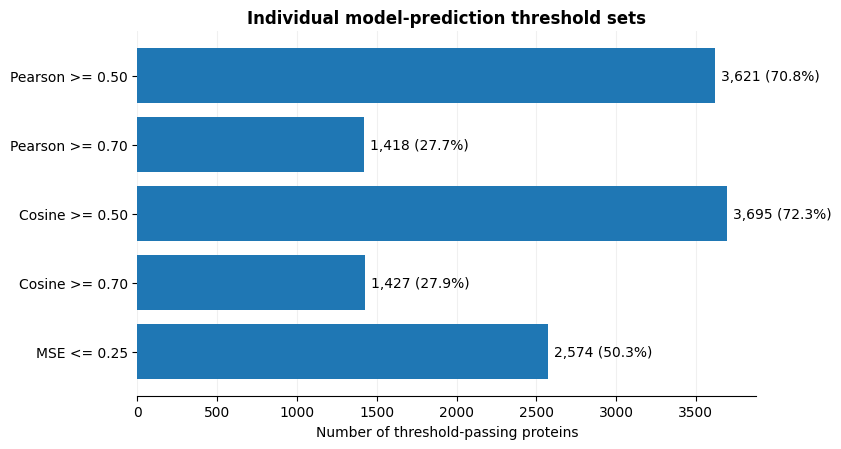

Saved plot: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\pan_atlas_outputs\plots\threshold_set_sizes.png


In [10]:

# 11. Visual overview of threshold set sizes

fig, ax = plt.subplots(figsize=(8.5, 4.6))
plot_df = threshold_summary.set_index("condition").reindex(condition_order).reset_index()
y = np.arange(len(plot_df))
ax.barh(y, plot_df["n_proteins"])
ax.set_yticks(y)
ax.set_yticklabels(plot_df["condition"])
ax.invert_yaxis()
ax.set_xlabel("Number of threshold-passing proteins")
ax.set_title("Individual model-prediction threshold sets", fontweight="bold")
for yi, r in enumerate(plot_df.itertuples(index=False)):
    ax.text(r.n_proteins + max(plot_df["n_proteins"].max() * 0.01, 1), yi, f"{int(r.n_proteins):,} ({r.pct_of_universe:.1f}%)", va="center")
ax.grid(axis="x", alpha=0.18)
ax.set_axisbelow(True)
for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)
plt.tight_layout()
savefig("threshold_set_sizes.png")


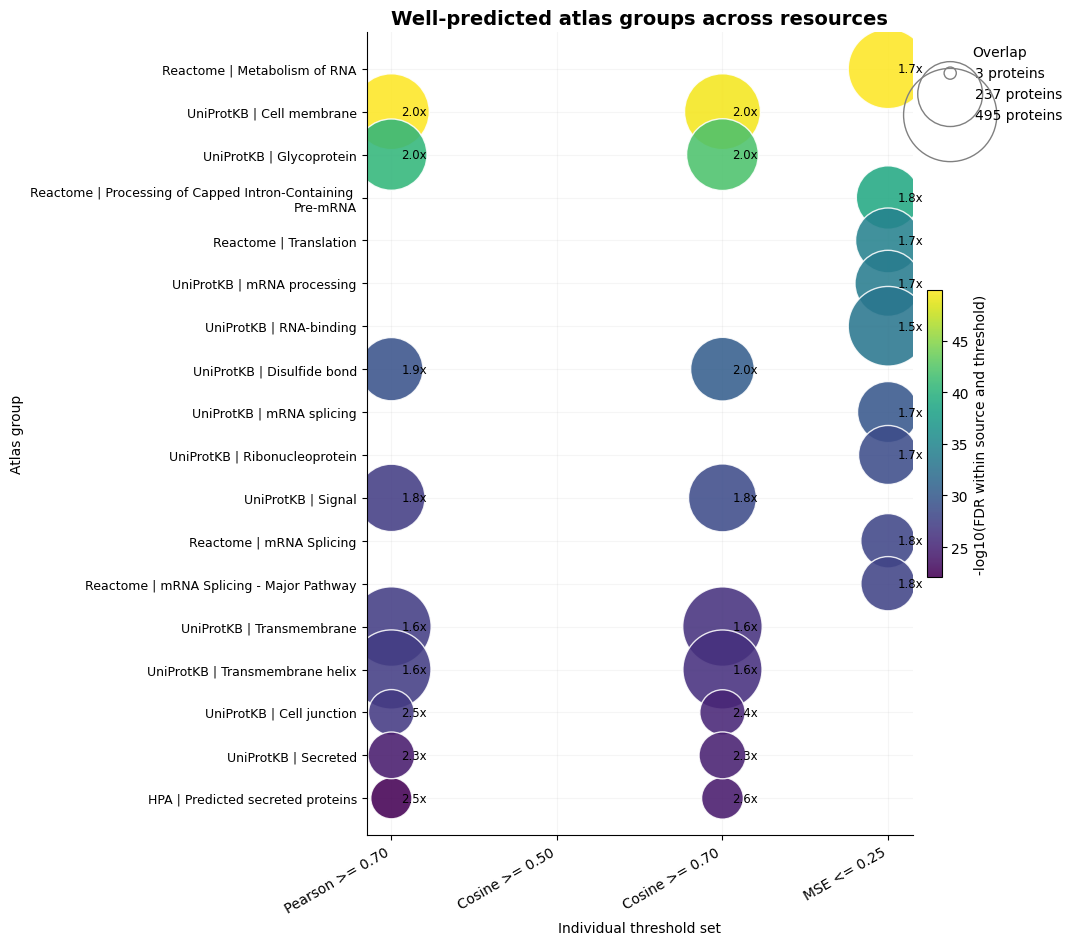

Saved plot: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\pan_atlas_outputs\plots\well_predicted_atlas_groups_bubble_matrix_all_sources.png


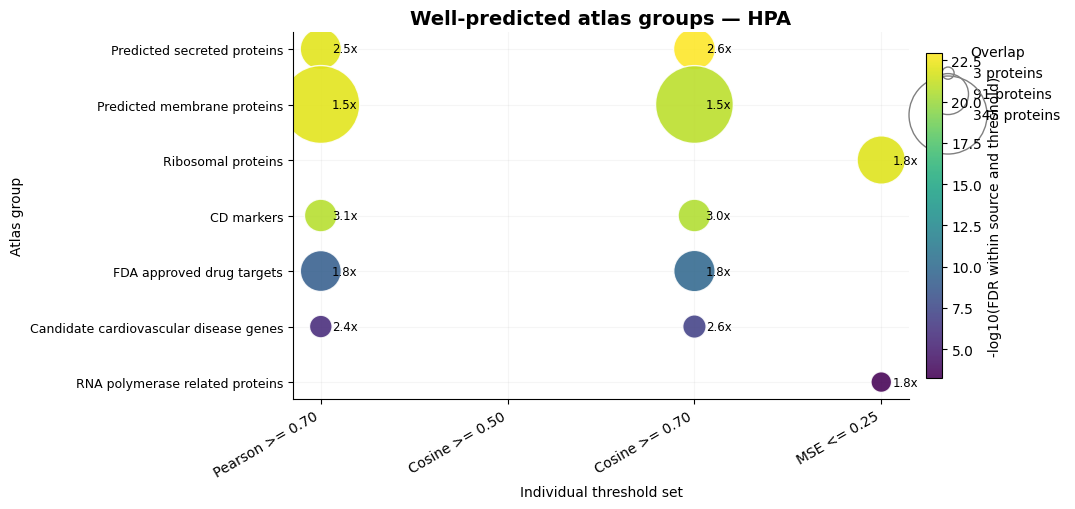

Saved plot: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\pan_atlas_outputs\plots\well_predicted_atlas_groups_bubble_matrix_hpa.png


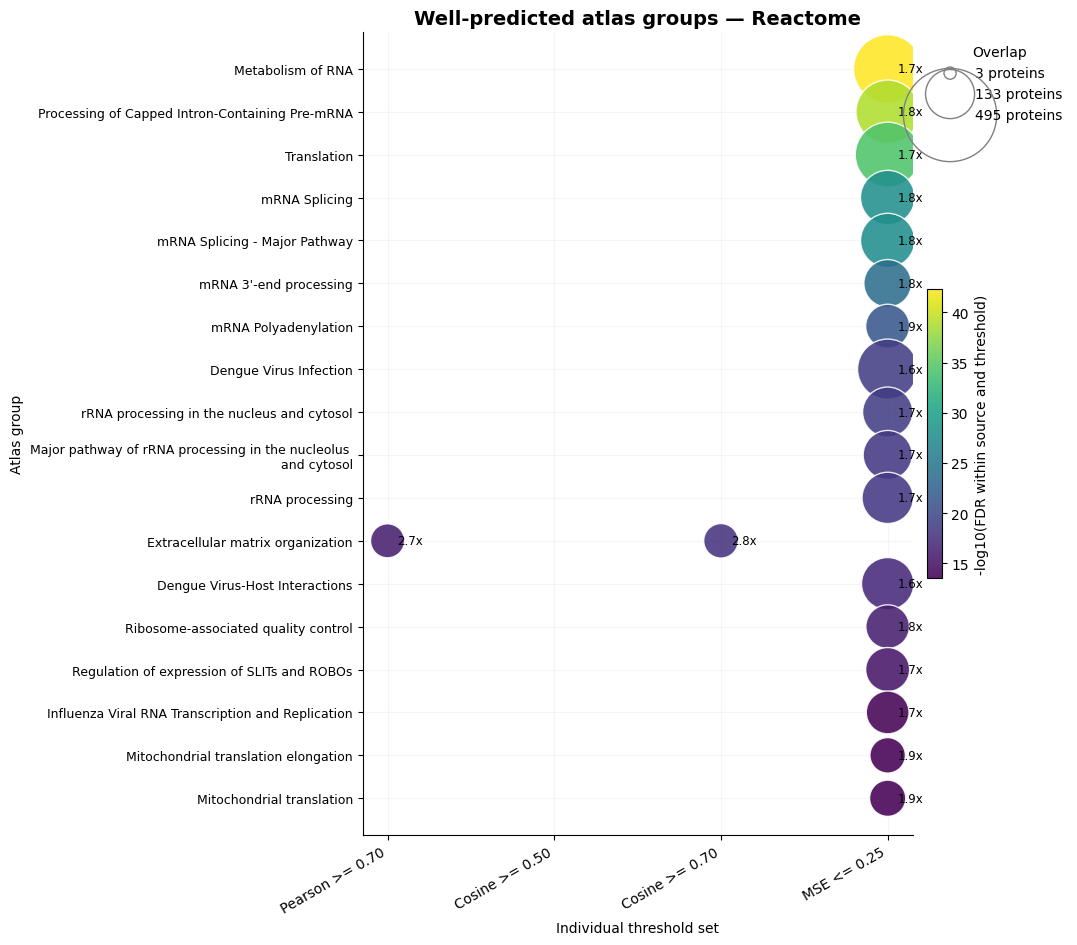

Saved plot: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\pan_atlas_outputs\plots\well_predicted_atlas_groups_bubble_matrix_reactome.png


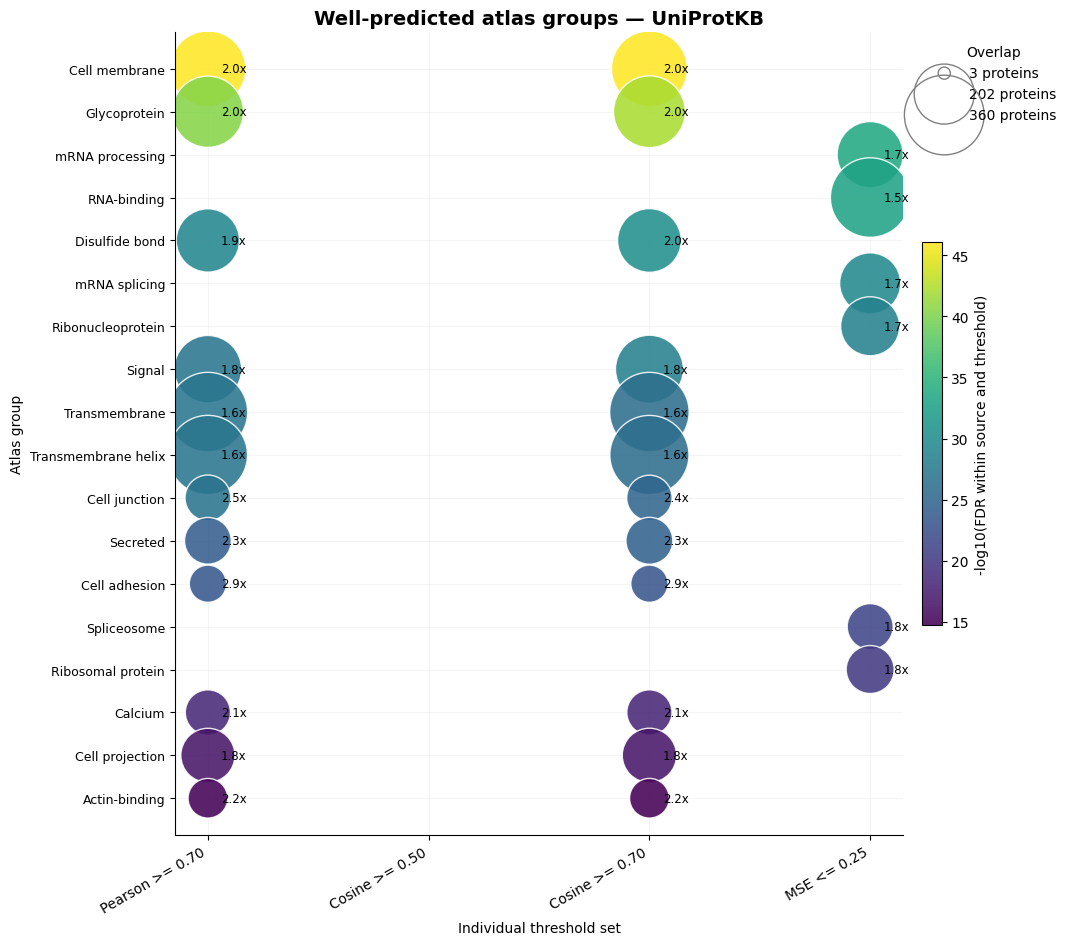

Saved plot: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\pan_atlas_outputs\plots\well_predicted_atlas_groups_bubble_matrix_uniprotkb.png


In [11]:

# 12. Main pan-atlas visualization: enriched groups across threshold sets


def wrap_text(x, width=46):
    return "\n".join(re.findall(r".{1,%d}(?:\s+|$)" % width, str(x))) or str(x)


def plot_enriched_group_bubble_matrix(source=None, top_n=TOP_N_GROUPS_PER_PLOT, only_well=True):
    if enrichment.empty:
        print("No enrichment data to plot.")
        return
    df = enrichment.copy()
    if source is not None:
        df = df.loc[df["source"] == source].copy()
    if only_well:
        df = df.loc[df["well_predicted_group"]].copy()
    if df.empty:
        print(f"No {'well-predicted ' if only_well else ''}groups to plot for source={source}.")
        return

    # Select groups by minimum FDR then fold and overlap.
    group_rank = (
        df.groupby(["source", "group_id", "group_name"], as_index=False)
        .agg(
            best_fdr=("fdr_within_source_condition", "min"),
            max_fold=("fold_enrichment", "max"),
            max_overlap=("overlap_n", "max"),
        )
        .sort_values(["best_fdr", "max_fold", "max_overlap"], ascending=[True, False, False])
        .head(top_n)
    )
    keep = set(group_rank["group_id"])
    plot = df.loc[df["group_id"].isin(keep)].copy()

    # Better row labels.
    group_labels = (
        group_rank.assign(label=lambda x: np.where(source is None, x["source"] + " | " + x["group_name"], x["group_name"]))
        .set_index("group_id")["label"]
        .to_dict()
    )
    ordered_groups = group_rank["group_id"].tolist()[::-1]
    group_pos = {g: i for i, g in enumerate(ordered_groups)}
    cond_pos = {c: i for i, c in enumerate(condition_order)}

    plot["x"] = plot["condition"].map(cond_pos)
    plot["y"] = plot["group_id"].map(group_pos)
    plot = plot.dropna(subset=["x", "y"])

    # Color = -log10 FDR, size = overlap.
    fdr = plot["fdr_within_source_condition"].replace(0, np.nan)
    neglog = -np.log10(fdr.fillna(fdr[fdr > 0].min() if (fdr > 0).any() else 1e-300))
    neglog = neglog.clip(upper=np.nanpercentile(neglog, 95) if len(neglog) > 2 else neglog.max())
    sizes = 50 + plot["overlap_n"].clip(upper=plot["overlap_n"].quantile(0.95)) * 9

    fig_h = max(5.2, 0.42 * len(ordered_groups) + 2.0)
    fig_w = 10.8
    fig, ax = plt.subplots(figsize=(fig_w, fig_h))
    sc = ax.scatter(
        plot["x"], plot["y"],
        s=sizes,
        c=neglog,
        cmap="viridis",
        alpha=0.88,
        edgecolors="white",
        linewidth=1.0,
    )

    # Put fold enrichment as compact text inside/next to points.
    for r in plot.itertuples(index=False):
        ax.text(r.x + 0.06, r.y, f"{r.fold_enrichment:.1f}x", va="center", fontsize=8.5)

    ax.set_xticks(range(len(condition_order)))
    ax.set_xticklabels(condition_order, rotation=30, ha="right")
    ax.set_yticks(range(len(ordered_groups)))
    ax.set_yticklabels([wrap_text(group_labels[g], 52) for g in ordered_groups], fontsize=9)
    ax.set_title(
        f"Well-predicted atlas groups" + (f" — {source}" if source else " across resources"),
        fontsize=14,
        fontweight="bold",
    )
    ax.set_xlabel("Individual threshold set")
    ax.set_ylabel("Atlas group")
    ax.grid(axis="both", alpha=0.12)
    ax.set_axisbelow(True)
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)
    cbar = fig.colorbar(sc, ax=ax, fraction=0.025, pad=0.025)
    cbar.set_label("-log10(FDR within source and threshold)")

    # Size legend.
    handles = []
    for n in [MIN_OVERLAP, max(MIN_OVERLAP + 2, int(plot["overlap_n"].median())), int(plot["overlap_n"].max())]:
        handles.append(plt.scatter([], [], s=50 + n * 9, facecolors="none", edgecolors="gray", label=f"{n} proteins"))
    ax.legend(handles=handles, title="Overlap", loc="upper left", bbox_to_anchor=(1.02, 1), frameon=False)

    plt.tight_layout()
    suffix = safe_slug(source) if source else "all_sources"
    savefig(f"well_predicted_atlas_groups_bubble_matrix_{suffix}.png")

plot_enriched_group_bubble_matrix(source=None, top_n=TOP_N_GROUPS_PER_PLOT, only_well=True)

# Also generate one plot per major source if enough groups pass.
for src in sorted(enrichment["source"].dropna().unique()) if not enrichment.empty else []:
    n_src_well = int(((enrichment["source"] == src) & enrichment["well_predicted_group"]).sum())
    if n_src_well >= 3:
        plot_enriched_group_bubble_matrix(source=src, top_n=TOP_N_GROUPS_PER_PLOT, only_well=True)


No well-predicted groups for Pearson >= 0.50.


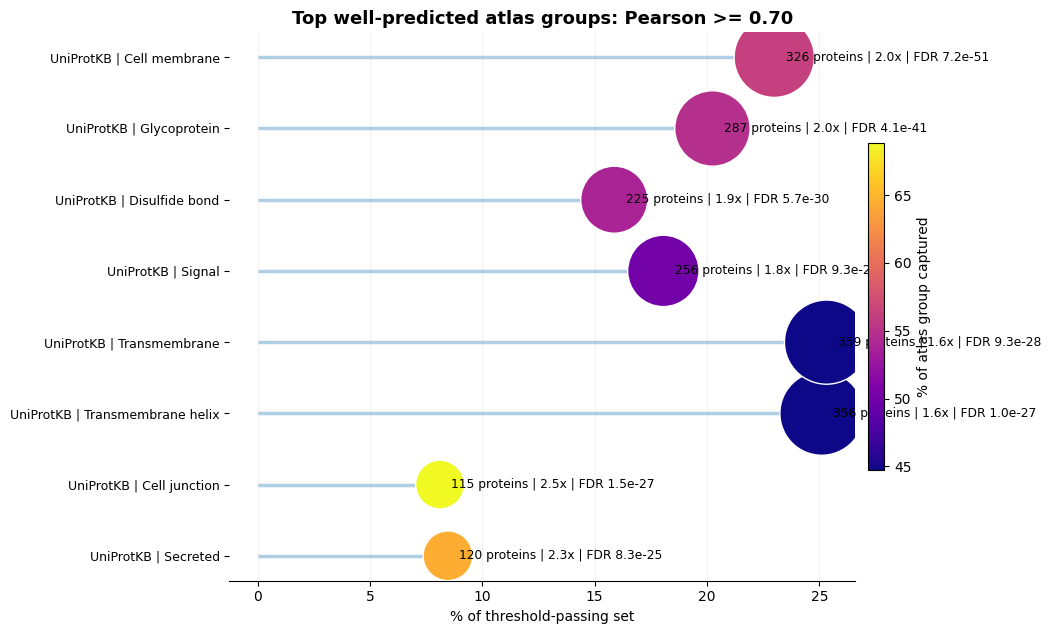

Saved plot: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\pan_atlas_outputs\plots\top_well_predicted_groups_pearson_0_70.png
No well-predicted groups for Cosine >= 0.50.


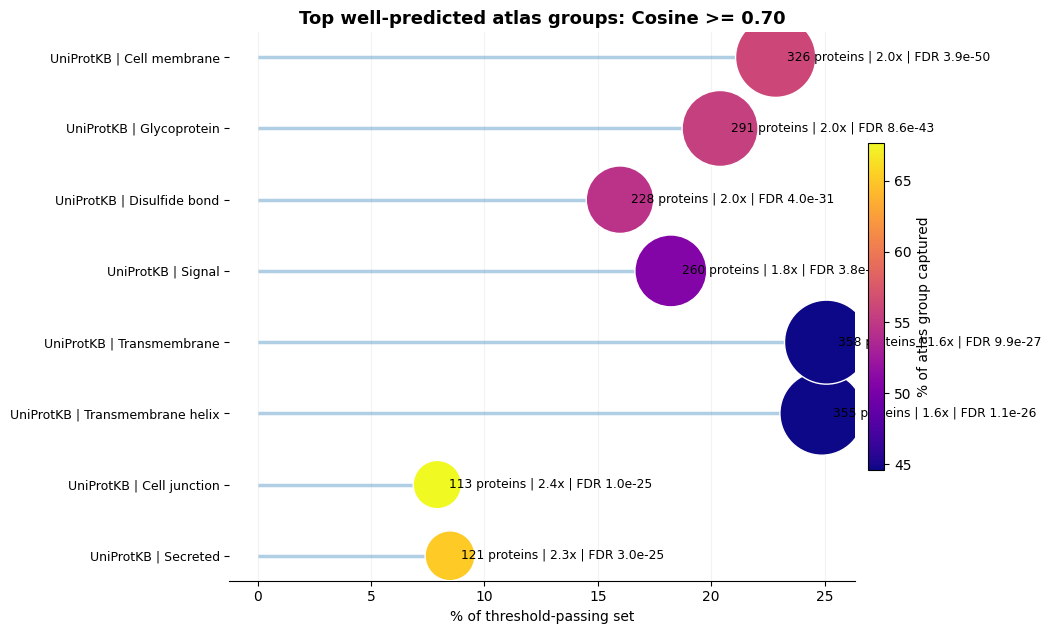

Saved plot: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\pan_atlas_outputs\plots\top_well_predicted_groups_cosine_0_70.png


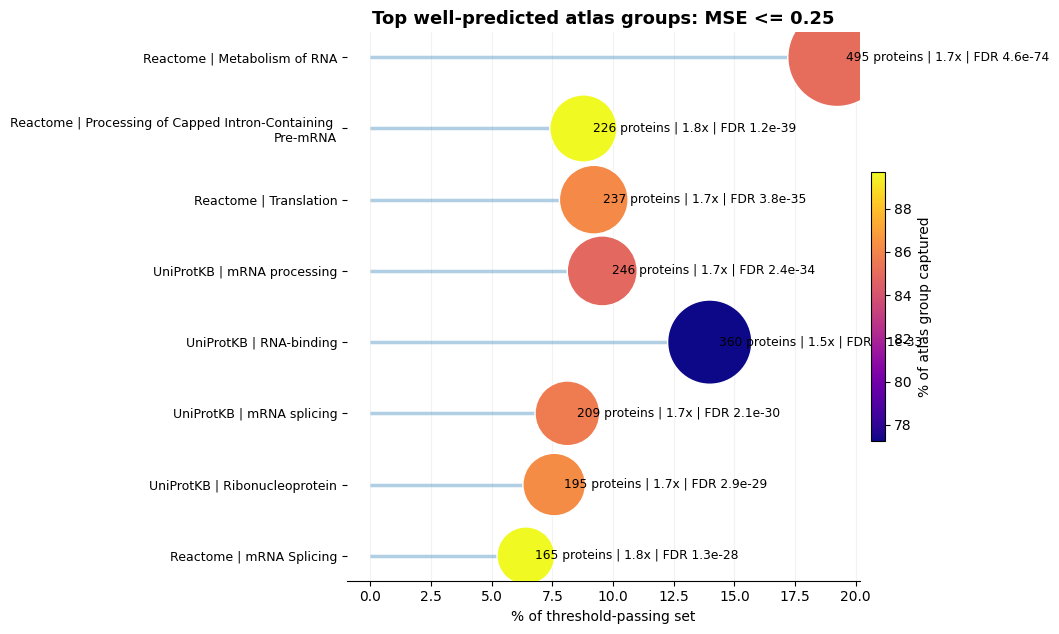

Saved plot: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\pan_atlas_outputs\plots\top_well_predicted_groups_mse_0_25.png


In [12]:

# 13. Top groups per threshold set: percent of set versus percent of atlas group captured


def plot_top_groups_per_condition(max_groups=8):
    if enrichment.empty:
        print("No enrichment data to plot.")
        return
    for cond in condition_order:
        df = (
            enrichment.loc[(enrichment["condition"] == cond) & enrichment["well_predicted_group"]]
            .sort_values(["fdr_within_source_condition", "fold_enrichment", "overlap_n"], ascending=[True, False, False])
            .head(max_groups)
            .copy()
        )
        if df.empty:
            print(f"No well-predicted groups for {cond}.")
            continue
        df = df.iloc[::-1].copy()
        labels = (df["source"] + " | " + df["group_name"]).map(lambda x: wrap_text(x, 50))
        y = np.arange(len(df))

        fig, ax = plt.subplots(figsize=(10.5, max(4.6, 0.58 * len(df) + 1.8)))
        ax.hlines(y, 0, df["pct_of_threshold_set"], linewidth=2.5, alpha=0.35)
        sc = ax.scatter(
            df["pct_of_threshold_set"], y,
            s=80 + df["overlap_n"] * 10,
            c=df["pct_of_atlas_group_captured"],
            cmap="plasma",
            edgecolors="white",
            linewidth=1.0,
            zorder=3,
        )
        for yi, r in enumerate(df.itertuples(index=False)):
            ax.text(
                r.pct_of_threshold_set + max(0.3, df["pct_of_threshold_set"].max() * 0.02), yi,
                f"{int(r.overlap_n)} proteins | {r.fold_enrichment:.1f}x | FDR {r.fdr_within_source_condition:.1e}",
                va="center", fontsize=8.8,
            )
        ax.set_yticks(y)
        ax.set_yticklabels(labels, fontsize=9)
        ax.set_xlabel("% of threshold-passing set")
        ax.set_title(f"Top well-predicted atlas groups: {cond}", fontsize=13, fontweight="bold")
        ax.grid(axis="x", alpha=0.16)
        ax.set_axisbelow(True)
        for spine in ["top", "right", "left"]:
            ax.spines[spine].set_visible(False)
        cbar = fig.colorbar(sc, ax=ax, fraction=0.025, pad=0.02)
        cbar.set_label("% of atlas group captured")
        plt.tight_layout()
        savefig(f"top_well_predicted_groups_{safe_slug(cond)}.png")

plot_top_groups_per_condition(max_groups=8)


Pan-atlas enrichment summary

Pearson >= 0.50 | 3,621 proteins | 0 enriched atlas groups
  1. UniProtKB | Membrane -- overlap 1,329, 36.7% of set, 81.5% of atlas group, 1.15x, FDR 2.08e-29
  2. UniProtKB | Transmembrane helix -- overlap 691, 19.1% of set, 86.9% of atlas group, 1.23x, FDR 1.20e-28
  3. UniProtKB | Transmembrane -- overlap 697, 19.2% of set, 86.8% of atlas group, 1.23x, FDR 1.20e-28

Pearson >= 0.70 | 1,418 proteins | 249 enriched atlas groups
  1. UniProtKB | Cell membrane -- overlap 326, 23.0% of set, 56.2% of atlas group, 2.03x, FDR 7.17e-51
  2. UniProtKB | Glycoprotein -- overlap 287, 20.2% of set, 54.8% of atlas group, 1.97x, FDR 4.06e-41
  3. UniProtKB | Membrane -- overlap 647, 45.6% of set, 39.7% of atlas group, 1.43x, FDR 1.10e-35

Cosine >= 0.50 | 3,695 proteins | 0 enriched atlas groups
  1. UniProtKB | Membrane -- overlap 1,353, 36.6% of set, 83.0% of atlas group, 1.15x, FDR 1.14e-30
  2. UniProtKB | Transmembrane -- overlap 700, 18.9% of set, 87.2% of atlas

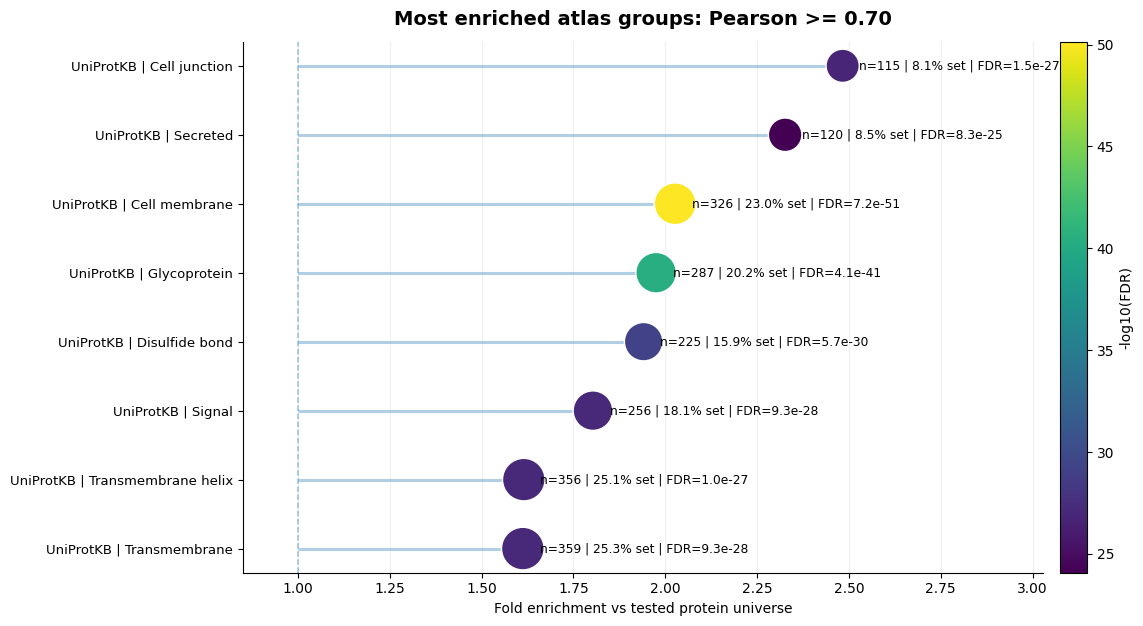

Saved: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\pan_atlas_outputs\plots\clean_ranked_enrichment_pearson_0_70.png


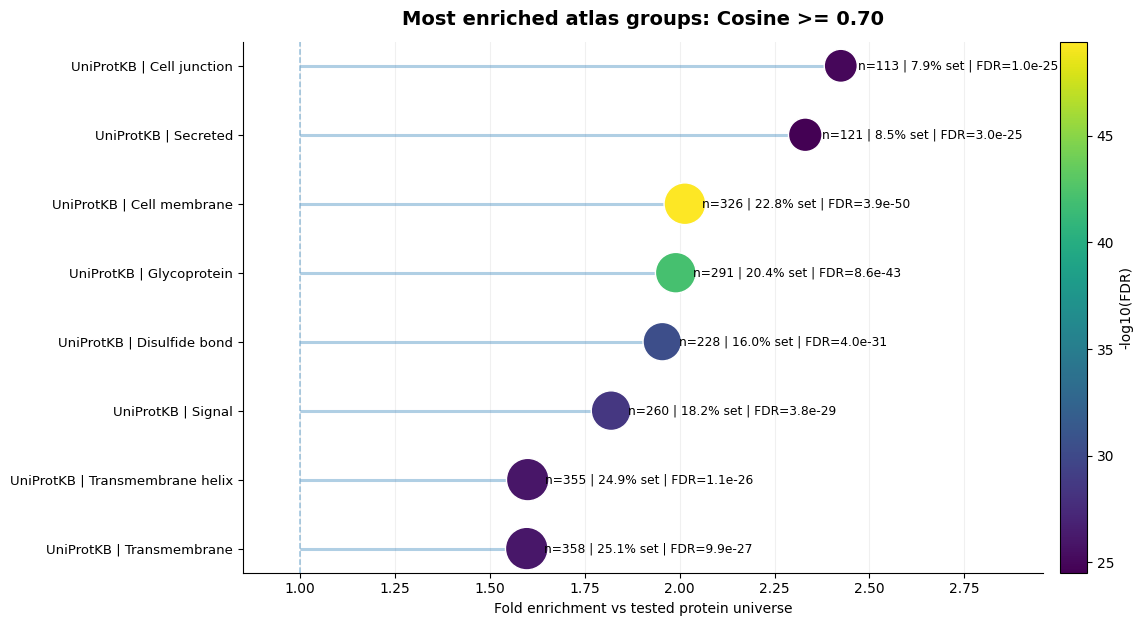

Saved: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\pan_atlas_outputs\plots\clean_ranked_enrichment_cosine_0_70.png


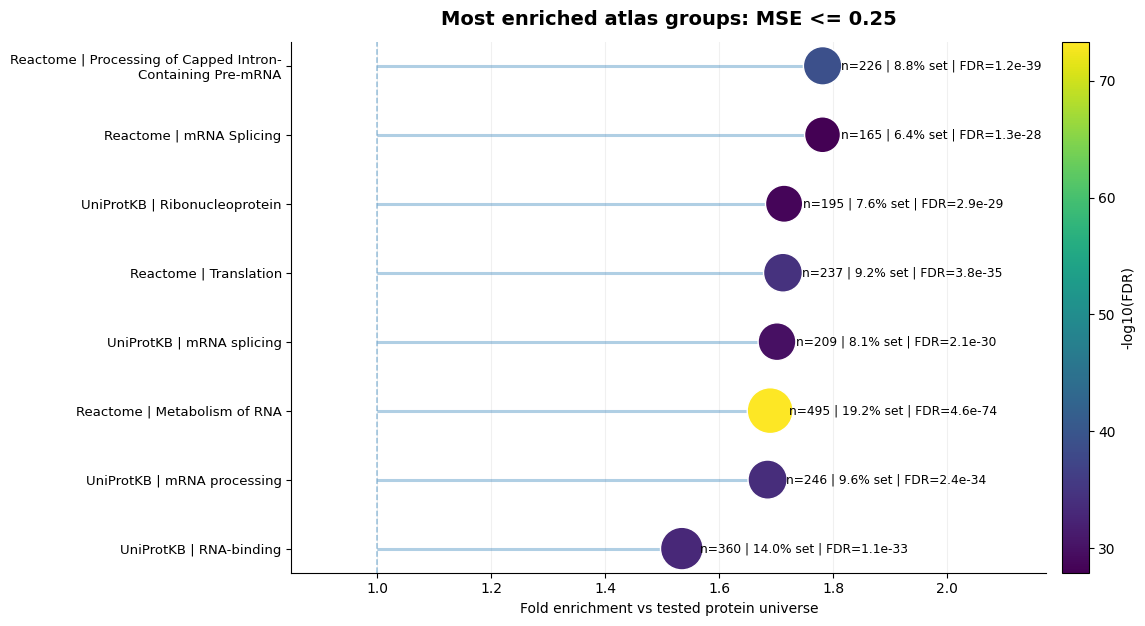

Saved: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\pan_atlas_outputs\plots\clean_ranked_enrichment_mse_0_25.png


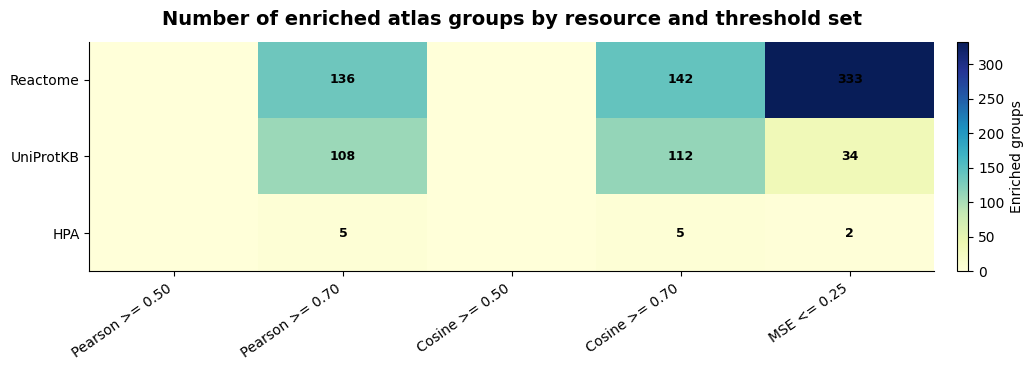

Saved: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\pan_atlas_outputs\plots\clean_source_by_threshold_enriched_group_heatmap.png


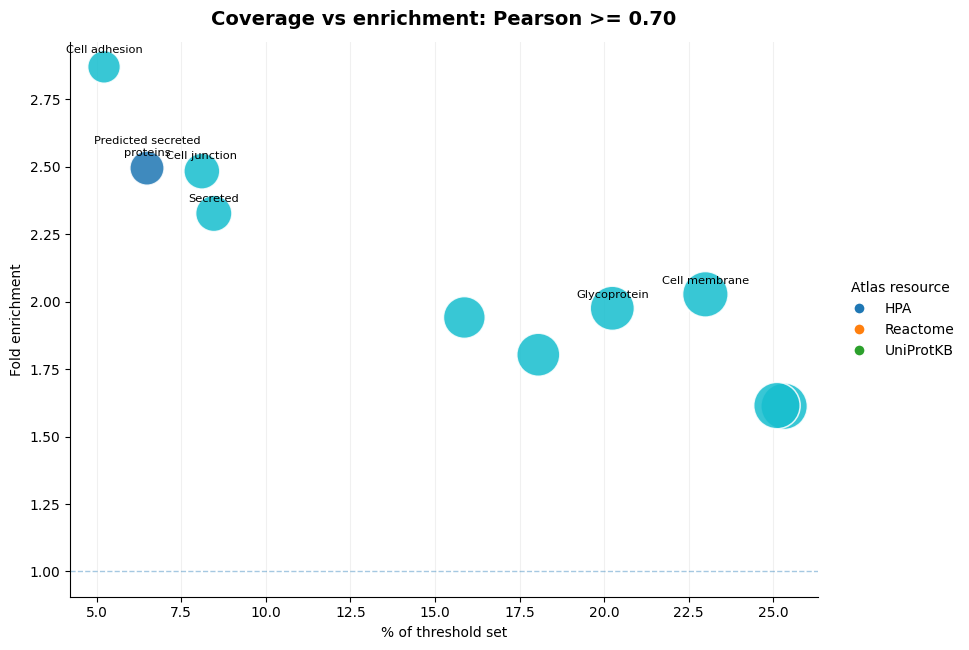

Saved: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\pan_atlas_outputs\plots\clean_coverage_enrichment_landscape_pearson_0_70.png


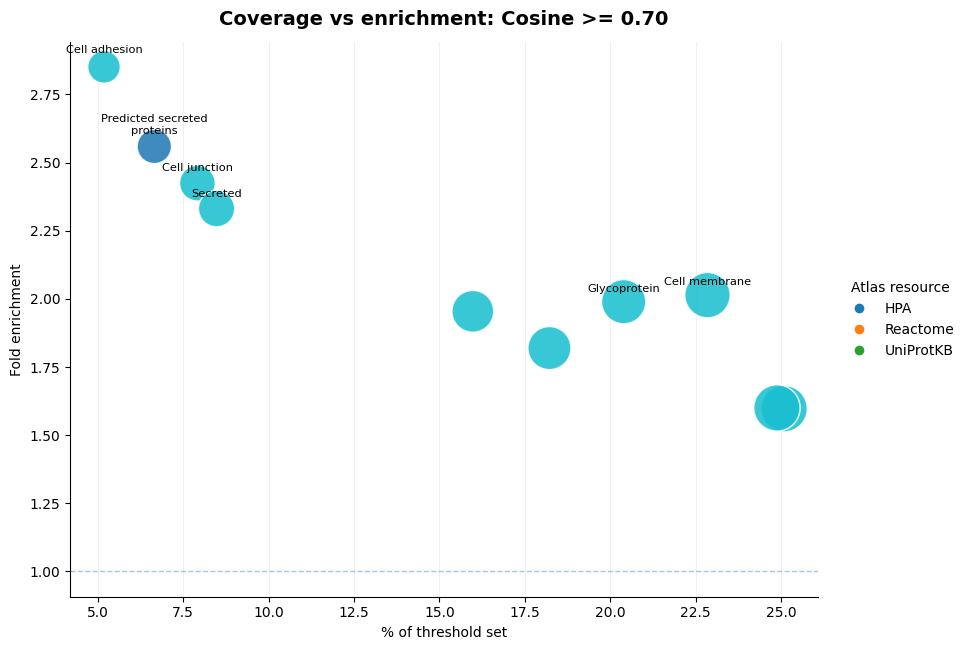

Saved: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\pan_atlas_outputs\plots\clean_coverage_enrichment_landscape_cosine_0_70.png


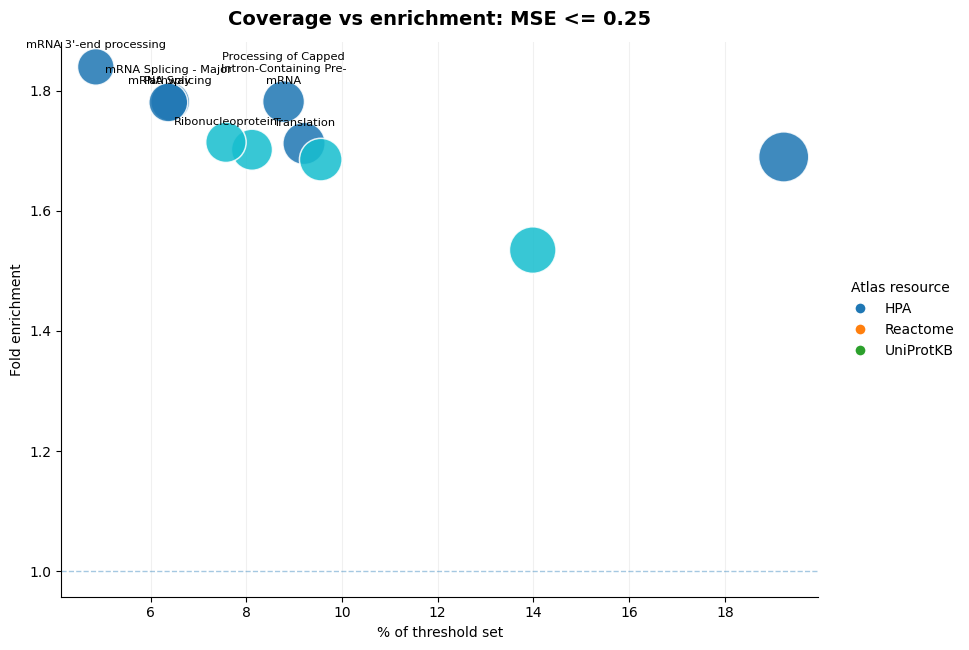

Saved: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\pan_atlas_outputs\plots\clean_coverage_enrichment_landscape_mse_0_25.png


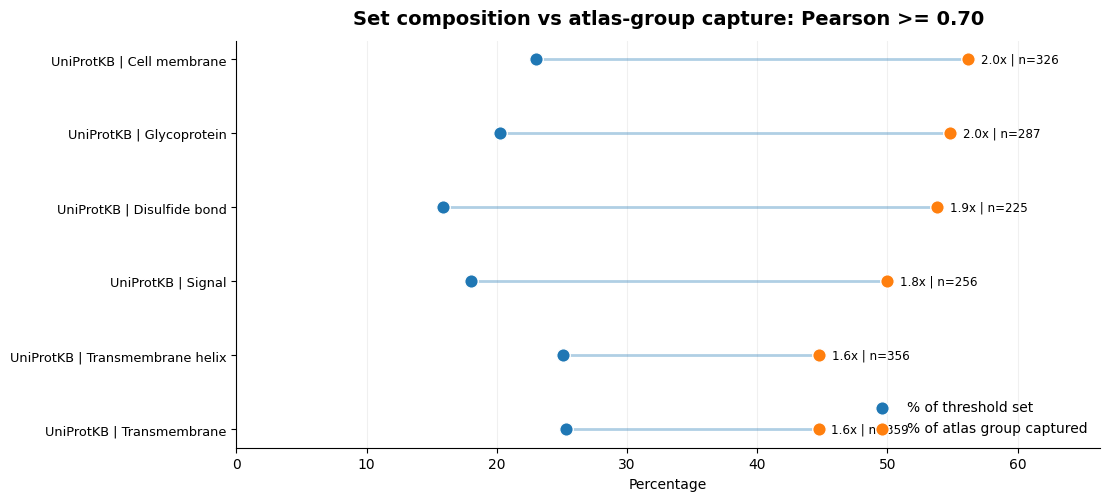

Saved: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\pan_atlas_outputs\plots\clean_dumbbell_percentages_pearson_0_70.png


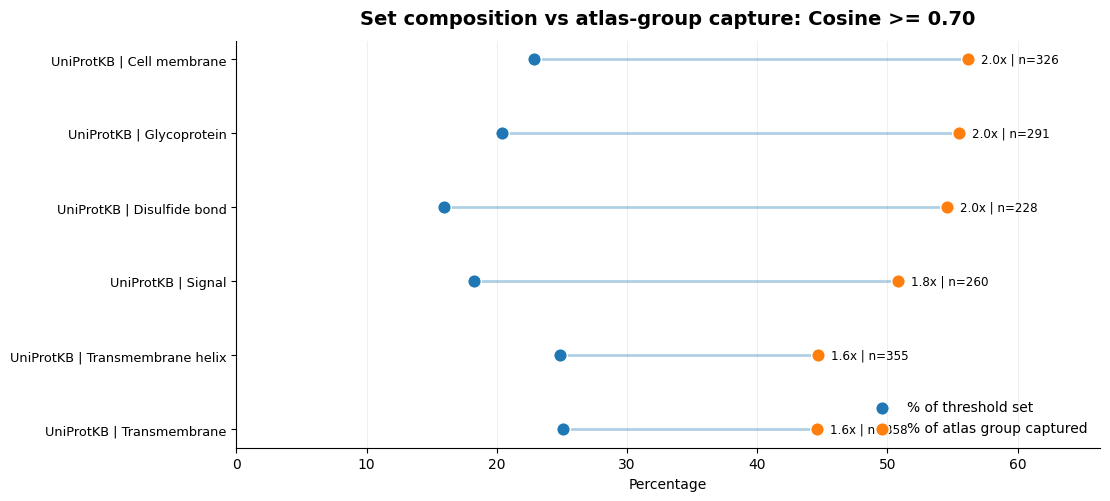

Saved: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\pan_atlas_outputs\plots\clean_dumbbell_percentages_cosine_0_70.png


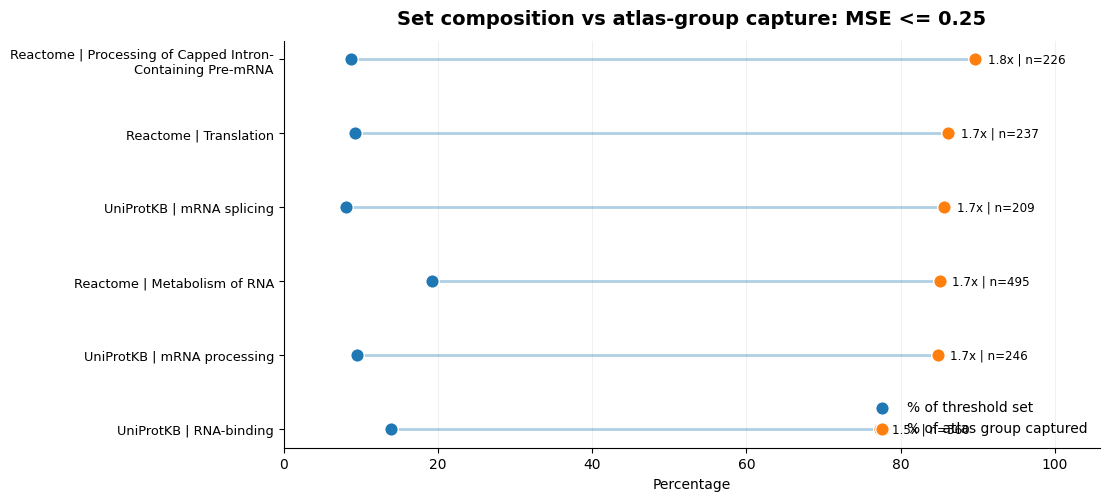

Saved: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\pan_atlas_outputs\plots\clean_dumbbell_percentages_mse_0_25.png


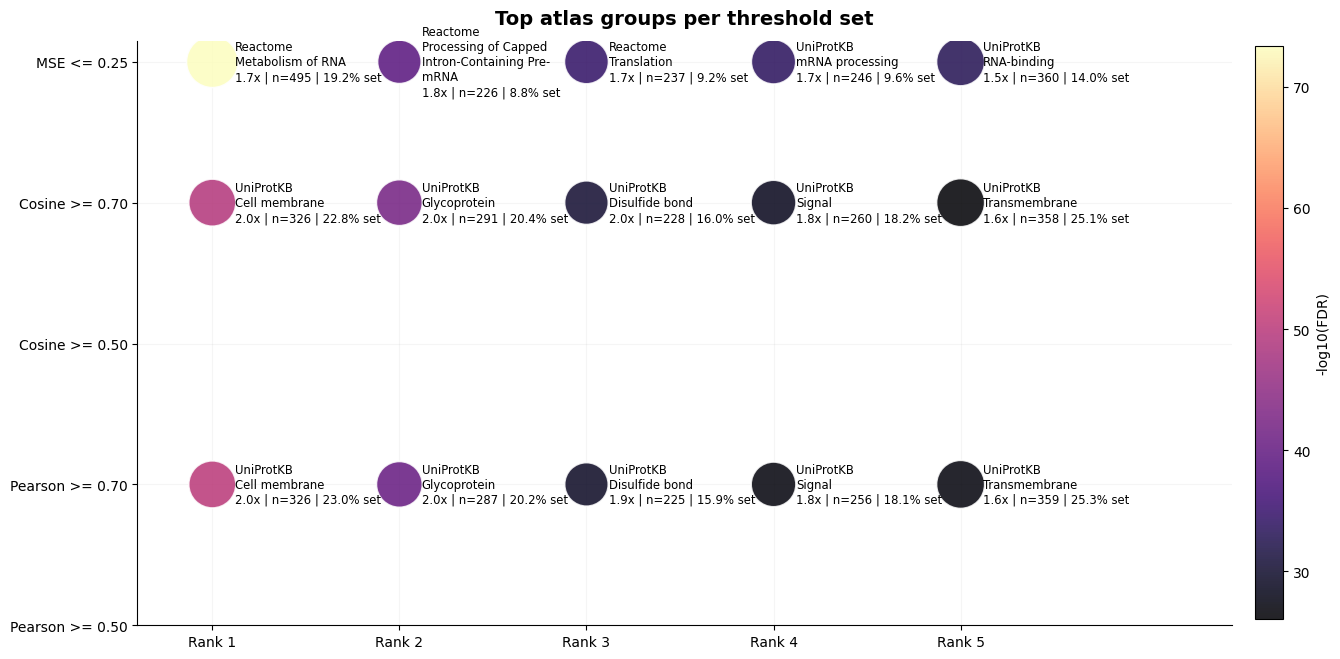

Saved: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\pan_atlas_outputs\plots\clean_top_atlas_group_tiles.png


In [15]:
# Clean pan-atlas visualization cell
# Paste after enrichment has been computed.
#
# Expected existing objects:
#   enrichment
#   threshold_summary
#   condition_order
#   PLOTS_DIR
#   TABLES_DIR

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import textwrap
import re
from pathlib import Path


# ---------------------------------------------------------------------
# General style helpers
# ---------------------------------------------------------------------

PLOTS_DIR = Path(PLOTS_DIR)
PLOTS_DIR.mkdir(parents=True, exist_ok=True)


def clean_slug(x):
    return re.sub(r"[^A-Za-z0-9]+", "_", str(x)).strip("_").lower()


def wrap_text(x, width=42):
    return "\n".join(textwrap.wrap(str(x), width=width))


def save_clean_fig(filename, dpi=260):
    out = PLOTS_DIR / filename
    plt.savefig(out, dpi=dpi, bbox_inches="tight", facecolor="white")
    plt.show()
    print(f"Saved: {out}")


def add_panel_style(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis="x", alpha=0.18)
    ax.set_axisbelow(True)


def pick_plot_df(
    enrichment,
    max_groups_per_condition=8,
    only_well_predicted=True,
    fallback_to_top=True,
):
    """
    Pick a readable subset of groups for plotting.
    Uses well_predicted_group when available, otherwise top FDR/enrichment groups.
    """
    if enrichment.empty:
        return pd.DataFrame()

    df = enrichment.copy()

    required = [
        "condition",
        "source",
        "collection",
        "group_name",
        "overlap_n",
        "set_size",
        "group_size_in_universe",
        "pct_of_threshold_set",
        "pct_of_atlas_group_captured",
        "fold_enrichment",
        "fdr_within_source_condition",
    ]
    missing = [c for c in required if c not in df.columns]
    if missing:
        raise ValueError(f"Missing expected enrichment columns: {missing}")

    df = df.replace([np.inf, -np.inf], np.nan)
    df = df.dropna(subset=["condition", "group_name", "fold_enrichment", "fdr_within_source_condition"])

    if only_well_predicted and "well_predicted_group" in df.columns:
        plot_df = df.loc[df["well_predicted_group"]].copy()
    else:
        plot_df = df.copy()

    if plot_df.empty and fallback_to_top:
        plot_df = df.copy()

    plot_df = (
        plot_df
        .sort_values(
            ["condition", "fdr_within_source_condition", "fold_enrichment", "overlap_n"],
            ascending=[True, True, False, False],
        )
        .groupby("condition", group_keys=False)
        .head(max_groups_per_condition)
        .copy()
    )

    plot_df["group_label"] = plot_df["source"].astype(str) + " | " + plot_df["group_name"].astype(str)
    plot_df["neglog10_fdr"] = -np.log10(plot_df["fdr_within_source_condition"].clip(lower=1e-300))

    return plot_df


def print_clean_pan_atlas_summary(enrichment, threshold_summary, condition_order, fdr_cutoff=0.05):
    """
    Concise text summary instead of large display tables.
    """
    if enrichment.empty:
        print("No enrichment results available.")
        return

    print("Pan-atlas enrichment summary")
    print("=" * 64)

    ts = threshold_summary.set_index("condition") if not threshold_summary.empty else pd.DataFrame()

    for condition in condition_order:
        sub = enrichment.loc[enrichment["condition"] == condition].copy()

        if sub.empty:
            print(f"\n{condition}: no enrichment results.")
            continue

        n_set = None
        if not ts.empty and condition in ts.index and "n_proteins" in ts.columns:
            n_set = int(ts.loc[condition, "n_proteins"])

        if "well_predicted_group" in sub.columns:
            n_well = int(sub["well_predicted_group"].sum())
        else:
            n_well = int((sub["fdr_within_source_condition"] <= fdr_cutoff).sum())

        best = sub.sort_values(
            ["fdr_within_source_condition", "fold_enrichment", "overlap_n"],
            ascending=[True, False, False],
        ).head(3)

        size_txt = f"{n_set:,} proteins" if n_set is not None else "set size unavailable"
        print(f"\n{condition} | {size_txt} | {n_well:,} enriched atlas groups")

        for i, r in enumerate(best.itertuples(index=False), start=1):
            print(
                f"  {i}. {r.source} | {r.group_name} "
                f"-- overlap {int(r.overlap_n):,}, "
                f"{r.pct_of_threshold_set:.1f}% of set, "
                f"{r.pct_of_atlas_group_captured:.1f}% of atlas group, "
                f"{r.fold_enrichment:.2f}x, "
                f"FDR {r.fdr_within_source_condition:.2e}"
            )


# ---------------------------------------------------------------------
# Plot 1: Per-threshold clean ranked cards
# ---------------------------------------------------------------------

def plot_ranked_enrichment_cards(
    enrichment,
    condition_order,
    max_groups=8,
    only_well_predicted=True,
):
    """
    One clear horizontal ranked plot per threshold set.
    X-axis is fold enrichment.
    Label text gives overlap, % of set, and FDR.
    """
    plot_df = pick_plot_df(
        enrichment,
        max_groups_per_condition=max_groups,
        only_well_predicted=only_well_predicted,
        fallback_to_top=True,
    )

    if plot_df.empty:
        print("No enrichment rows available for ranked plots.")
        return

    for condition in condition_order:
        sub = plot_df.loc[plot_df["condition"] == condition].copy()

        if sub.empty:
            continue

        sub = sub.sort_values("fold_enrichment", ascending=True).copy()
        y = np.arange(len(sub))

        fig, ax = plt.subplots(figsize=(11.5, max(4.6, 0.62 * len(sub) + 1.4)))

        # Lollipop stems
        ax.hlines(
            y=y,
            xmin=1,
            xmax=sub["fold_enrichment"],
            linewidth=2.2,
            alpha=0.35,
        )

        sizes = 90 + np.sqrt(sub["overlap_n"].clip(lower=1)) * 45

        sc = ax.scatter(
            sub["fold_enrichment"],
            y,
            s=sizes,
            c=sub["neglog10_fdr"],
            cmap="viridis",
            edgecolors="white",
            linewidth=1.0,
            zorder=3,
        )

        ax.axvline(1, linestyle="--", linewidth=1.1, alpha=0.45)

        labels = [
            wrap_text(f"{r.source} | {r.group_name}", width=46)
            for r in sub.itertuples(index=False)
        ]

        ax.set_yticks(y)
        ax.set_yticklabels(labels, fontsize=9.5)

        ax.set_xlabel("Fold enrichment vs tested protein universe")
        ax.set_title(
            f"Most enriched atlas groups: {condition}",
            fontsize=14,
            fontweight="bold",
            pad=12,
        )

        add_panel_style(ax)

        x_max = max(1.5, sub["fold_enrichment"].max() * 1.22)
        ax.set_xlim(0.85, x_max)

        for yi, r in enumerate(sub.itertuples(index=False)):
            txt = (
                f"n={int(r.overlap_n):,} | "
                f"{r.pct_of_threshold_set:.1f}% set | "
                f"FDR={r.fdr_within_source_condition:.1e}"
            )
            ax.text(
                r.fold_enrichment + x_max * 0.015,
                yi,
                txt,
                va="center",
                fontsize=8.8,
            )

        cbar = fig.colorbar(sc, ax=ax, pad=0.02, fraction=0.04)
        cbar.set_label("-log10(FDR)")

        plt.tight_layout()
        save_clean_fig(f"clean_ranked_enrichment_{clean_slug(condition)}.png")


# ---------------------------------------------------------------------
# Plot 2: Source contribution heatmap
# ---------------------------------------------------------------------

def plot_source_condition_heatmap(enrichment, condition_order, fdr_cutoff=0.05):
    """
    Compact heatmap:
    rows = atlas resources
    columns = threshold sets
    value = number of enriched groups.
    """
    if enrichment.empty:
        print("No enrichment rows available for source heatmap.")
        return

    df = enrichment.copy()

    if "well_predicted_group" in df.columns:
        df["is_hit"] = df["well_predicted_group"].astype(bool)
    else:
        df["is_hit"] = df["fdr_within_source_condition"] <= fdr_cutoff

    hit_counts = (
        df.loc[df["is_hit"]]
        .groupby(["source", "condition"])
        .size()
        .unstack("condition", fill_value=0)
        .reindex(columns=condition_order, fill_value=0)
    )

    if hit_counts.empty:
        print("No enriched groups available for source heatmap.")
        return

    # Sort sources by total hits.
    hit_counts = hit_counts.loc[hit_counts.sum(axis=1).sort_values(ascending=False).index]

    fig, ax = plt.subplots(figsize=(10.5, max(3.8, 0.48 * len(hit_counts) + 2.0)))

    im = ax.imshow(hit_counts.values, aspect="auto", cmap="YlGnBu")

    ax.set_xticks(range(len(hit_counts.columns)))
    ax.set_xticklabels(hit_counts.columns, rotation=35, ha="right")
    ax.set_yticks(range(len(hit_counts.index)))
    ax.set_yticklabels(hit_counts.index)

    ax.set_title(
        "Number of enriched atlas groups by resource and threshold set",
        fontsize=14,
        fontweight="bold",
        pad=12,
    )

    for i in range(hit_counts.shape[0]):
        for j in range(hit_counts.shape[1]):
            val = int(hit_counts.iloc[i, j])
            if val > 0:
                ax.text(j, i, str(val), ha="center", va="center", fontsize=9, fontweight="bold")

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    cbar = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.025)
    cbar.set_label("Enriched groups")

    plt.tight_layout()
    save_clean_fig("clean_source_by_threshold_enriched_group_heatmap.png")


# ---------------------------------------------------------------------
# Plot 3: Coverage-vs-enrichment landscape
# ---------------------------------------------------------------------

def plot_coverage_enrichment_landscape(
    enrichment,
    condition_order,
    max_groups_per_condition=10,
    only_well_predicted=True,
):
    """
    Scatter landscape:
    x = % of threshold set
    y = fold enrichment
    size = overlap
    color = source
    Faceted by condition in separate figures for readability.
    """
    plot_df = pick_plot_df(
        enrichment,
        max_groups_per_condition=max_groups_per_condition,
        only_well_predicted=only_well_predicted,
        fallback_to_top=True,
    )

    if plot_df.empty:
        print("No enrichment rows available for landscape plots.")
        return

    sources = sorted(plot_df["source"].dropna().astype(str).unique())
    source_to_int = {s: i for i, s in enumerate(sources)}

    for condition in condition_order:
        sub = plot_df.loc[plot_df["condition"] == condition].copy()
        if sub.empty:
            continue

        sub["source_code"] = sub["source"].astype(str).map(source_to_int)

        fig, ax = plt.subplots(figsize=(9.8, 6.6))

        sizes = 80 + np.sqrt(sub["overlap_n"].clip(lower=1)) * 55

        sc = ax.scatter(
            sub["pct_of_threshold_set"],
            sub["fold_enrichment"],
            s=sizes,
            c=sub["source_code"],
            cmap="tab10",
            alpha=0.86,
            edgecolors="white",
            linewidth=1.1,
        )

        ax.axhline(1, linestyle="--", linewidth=1.0, alpha=0.4)

        # Annotate only the most informative labels.
        label_sub = sub.sort_values(
            ["fold_enrichment", "pct_of_threshold_set", "overlap_n"],
            ascending=False,
        ).head(6)

        for r in label_sub.itertuples(index=False):
            ax.text(
                r.pct_of_threshold_set,
                r.fold_enrichment * 1.015,
                wrap_text(r.group_name, 24),
                fontsize=8.2,
                ha="center",
                va="bottom",
            )

        ax.set_xlabel("% of threshold set")
        ax.set_ylabel("Fold enrichment")
        ax.set_title(
            f"Coverage vs enrichment: {condition}",
            fontsize=14,
            fontweight="bold",
            pad=12,
        )

        add_panel_style(ax)

        # Legend for source colors
        handles = [
            plt.Line2D(
                [0],
                [0],
                marker="o",
                linestyle="",
                markersize=8,
                label=s,
                markerfacecolor=plt.get_cmap("tab10")(source_to_int[s] % 10),
                markeredgecolor="white",
            )
            for s in sources
        ]

        ax.legend(
            handles=handles,
            title="Atlas resource",
            loc="center left",
            bbox_to_anchor=(1.02, 0.5),
            frameon=False,
        )

        plt.tight_layout()
        save_clean_fig(f"clean_coverage_enrichment_landscape_{clean_slug(condition)}.png")


# ---------------------------------------------------------------------
# Plot 4: Two-percentage dumbbell plot
# ---------------------------------------------------------------------

def plot_threshold_vs_group_capture_dumbbells(
    enrichment,
    condition_order,
    max_groups_per_condition=6,
    only_well_predicted=True,
):
    """
    Dumbbell plot:
    left/right values compare:
      - % of threshold set
      - % of atlas group captured
    This helps interpret whether a group dominates the selected proteins
    or whether the threshold captures a large part of that atlas group.
    """
    plot_df = pick_plot_df(
        enrichment,
        max_groups_per_condition=max_groups_per_condition,
        only_well_predicted=only_well_predicted,
        fallback_to_top=True,
    )

    if plot_df.empty:
        print("No enrichment rows available for dumbbell plots.")
        return

    for condition in condition_order:
        sub = plot_df.loc[plot_df["condition"] == condition].copy()

        if sub.empty:
            continue

        sub = sub.sort_values("fold_enrichment", ascending=True).copy()
        sub["label"] = sub["source"].astype(str) + " | " + sub["group_name"].astype(str)

        y = np.arange(len(sub))
        x1 = sub["pct_of_threshold_set"].to_numpy()
        x2 = sub["pct_of_atlas_group_captured"].to_numpy()

        fig, ax = plt.subplots(figsize=(11.2, max(4.6, 0.62 * len(sub) + 1.4)))

        ax.hlines(y=y, xmin=np.minimum(x1, x2), xmax=np.maximum(x1, x2), linewidth=2.0, alpha=0.35)

        ax.scatter(
            x1,
            y,
            s=95,
            label="% of threshold set",
            edgecolors="white",
            linewidth=1.0,
            zorder=3,
        )

        ax.scatter(
            x2,
            y,
            s=95,
            label="% of atlas group captured",
            edgecolors="white",
            linewidth=1.0,
            zorder=3,
        )

        labels = [wrap_text(x, 48) for x in sub["label"]]
        ax.set_yticks(y)
        ax.set_yticklabels(labels, fontsize=9.3)

        ax.set_xlabel("Percentage")
        ax.set_title(
            f"Set composition vs atlas-group capture: {condition}",
            fontsize=14,
            fontweight="bold",
            pad=12,
        )

        add_panel_style(ax)
        ax.legend(frameon=False, loc="lower right")

        x_max = max(5, np.nanmax([x1.max(), x2.max()]) * 1.18)
        ax.set_xlim(0, x_max)

        for yi, r in enumerate(sub.itertuples(index=False)):
            ax.text(
                max(r.pct_of_threshold_set, r.pct_of_atlas_group_captured) + x_max * 0.015,
                yi,
                f"{r.fold_enrichment:.1f}x | n={int(r.overlap_n):,}",
                va="center",
                fontsize=8.6,
            )

        plt.tight_layout()
        save_clean_fig(f"clean_dumbbell_percentages_{clean_slug(condition)}.png")


# ---------------------------------------------------------------------
# Plot 5: Top groups as small multiples, no giant combined bubble plot
# ---------------------------------------------------------------------

def plot_top_group_tiles(
    enrichment,
    condition_order,
    max_groups_per_condition=5,
    only_well_predicted=True,
):
    """
    Tile-style plot:
    one compact row block per threshold set.
    Easier than the original all-in-one bubble chart.
    """
    plot_df = pick_plot_df(
        enrichment,
        max_groups_per_condition=max_groups_per_condition,
        only_well_predicted=only_well_predicted,
        fallback_to_top=True,
    )

    if plot_df.empty:
        print("No enrichment rows available for tile plot.")
        return

    rows = []
    for condition in condition_order:
        sub = plot_df.loc[plot_df["condition"] == condition].copy()
        sub = sub.sort_values(["fdr_within_source_condition", "fold_enrichment"], ascending=[True, False])
        for rank, r in enumerate(sub.itertuples(index=False), start=1):
            rows.append({
                "condition": condition,
                "rank": rank,
                "label": f"{r.source}\n{wrap_text(r.group_name, 24)}",
                "fold": r.fold_enrichment,
                "overlap": r.overlap_n,
                "fdr": r.fdr_within_source_condition,
                "pct_set": r.pct_of_threshold_set,
            })

    tile_df = pd.DataFrame(rows)
    if tile_df.empty:
        print("No tile rows available.")
        return

    fig, ax = plt.subplots(figsize=(13.5, max(5.0, 0.9 * len(condition_order) + 2.2)))

    x = tile_df["rank"].to_numpy()
    y = tile_df["condition"].map({c: i for i, c in enumerate(condition_order)}).to_numpy()
    color_val = -np.log10(tile_df["fdr"].clip(lower=1e-300))
    sizes = 160 + np.sqrt(tile_df["overlap"].clip(lower=1)) * 55

    sc = ax.scatter(
        x,
        y,
        s=sizes,
        c=color_val,
        cmap="magma",
        alpha=0.86,
        edgecolors="white",
        linewidth=1.2,
        zorder=3,
    )

    for r in tile_df.itertuples(index=False):
        yy = condition_order.index(r.condition)
        ax.text(
            r.rank + 0.12,
            yy,
            f"{r.label}\n{r.fold:.1f}x | n={int(r.overlap):,} | {r.pct_set:.1f}% set",
            va="center",
            ha="left",
            fontsize=8.4,
        )

    ax.set_xticks(range(1, max_groups_per_condition + 1))
    ax.set_xticklabels([f"Rank {i}" for i in range(1, max_groups_per_condition + 1)])
    ax.set_yticks(range(len(condition_order)))
    ax.set_yticklabels(condition_order)

    ax.set_xlim(0.6, max_groups_per_condition + 1.45)
    ax.set_title(
        "Top atlas groups per threshold set",
        fontsize=14,
        fontweight="bold",
        pad=12,
    )

    ax.grid(axis="both", alpha=0.12)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    cbar = fig.colorbar(sc, ax=ax, fraction=0.025, pad=0.02)
    cbar.set_label("-log10(FDR)")

    plt.tight_layout()
    save_clean_fig("clean_top_atlas_group_tiles.png")


# ---------------------------------------------------------------------
# Run all clean outputs
# ---------------------------------------------------------------------

print_clean_pan_atlas_summary(
    enrichment=enrichment,
    threshold_summary=threshold_summary,
    condition_order=condition_order,
    fdr_cutoff=0.05,
)

plot_ranked_enrichment_cards(
    enrichment=enrichment,
    condition_order=condition_order,
    max_groups=8,
    only_well_predicted=True,
)

plot_source_condition_heatmap(
    enrichment=enrichment,
    condition_order=condition_order,
    fdr_cutoff=0.05,
)

plot_coverage_enrichment_landscape(
    enrichment=enrichment,
    condition_order=condition_order,
    max_groups_per_condition=10,
    only_well_predicted=True,
)

plot_threshold_vs_group_capture_dumbbells(
    enrichment=enrichment,
    condition_order=condition_order,
    max_groups_per_condition=6,
    only_well_predicted=True,
)

plot_top_group_tiles(
    enrichment=enrichment,
    condition_order=condition_order,
    max_groups_per_condition=5,
    only_well_predicted=True,
)

In [14]:
# 14. Export clean top tables for interpretation

import json
from pathlib import Path

if enrichment.empty:
    print("No enrichment outputs to export.")
else:
    well = enrichment.loc[enrichment["well_predicted_group"]].copy()

    if well.empty:
        print("No atlas groups passed the current well-predicted criteria.")
        print("Exporting full enrichment table only.")
    else:
        well = well.sort_values(
            ["condition", "source", "fdr_within_source_condition", "fold_enrichment"],
            ascending=[True, True, True, False],
        )
        well.to_csv(TABLES_DIR / "well_predicted_atlas_groups.csv", index=False)

    top_per_condition_source = (
        enrichment.sort_values(
            ["condition", "source", "fdr_within_source_condition", "fold_enrichment"],
            ascending=[True, True, True, False],
        )
        .groupby(["condition", "source"], group_keys=False)
        .head(10)
        .copy()
    )

    top_per_condition_source.to_csv(
        TABLES_DIR / "top10_atlas_groups_per_condition_source.csv",
        index=False,
    )

    # Compact display table: top 3 examples per threshold set.
    compact_cols = [
        "condition",
        "source",
        "collection",
        "group_name",
        "overlap_n",
        "set_size",
        "group_size_in_universe",
        "pct_of_threshold_set",
        "pct_of_atlas_group_captured",
        "fold_enrichment",
        "fdr_within_source_condition",
    ]

    if well.empty:
        compact = (
            enrichment.sort_values(
                ["condition", "fdr_within_source_condition", "fold_enrichment"],
                ascending=[True, True, False],
            )
            .groupby("condition", group_keys=False)
            .head(3)
            [compact_cols]
            .copy()
        )

        print("No groups passed the well-predicted criteria.")
        print("Showing top 3 candidate groups per threshold set instead:")
    else:
        compact = (
            well.sort_values(
                ["condition", "fdr_within_source_condition", "fold_enrichment"],
                ascending=[True, True, False],
            )
            .groupby("condition", group_keys=False)
            .head(3)
            [compact_cols]
            .copy()
        )

        print("Top 3 well-predicted groups per threshold set:")

    display(compact)

    # Save metadata.
    if "PERFORMANCE_TABLE_PATHS" in globals() and PERFORMANCE_TABLE_PATHS:
        result_paths_for_meta = [str(Path(p)) for p in PERFORMANCE_TABLE_PATHS]
    elif "source_file" in perf.columns:
        result_paths_for_meta = sorted(perf["source_file"].dropna().astype(str).unique().tolist())
    else:
        result_paths_for_meta = []

    if "THRESHOLD_DEFINITIONS" in globals():
        threshold_defs_for_meta = THRESHOLD_DEFINITIONS
    else:
        threshold_defs_for_meta = {
            "Pearson >= 0.50": "pearson >= 0.50",
            "Pearson >= 0.70": "pearson >= 0.70",
            "Cosine >= 0.50": "cosine >= 0.50",
            "Cosine >= 0.70": "cosine >= 0.70",
            "MSE <= 0.25": "mse <= 0.25",
        }

    meta = {
        "result_paths": result_paths_for_meta,
        "universe_size_gene_symbols": int(N) if "N" in globals() else None,
        "threshold_definitions": threshold_defs_for_meta,
        "criteria": {
            "min_group_size_in_universe": MIN_GROUP_SIZE_IN_UNIVERSE if "MIN_GROUP_SIZE_IN_UNIVERSE" in globals() else None,
            "min_overlap": MIN_OVERLAP if "MIN_OVERLAP" in globals() else None,
            "fdr_cutoff": FDR_CUTOFF if "FDR_CUTOFF" in globals() else None,
            "fold_enrichment_cutoff": FOLD_ENRICHMENT_CUTOFF if "FOLD_ENRICHMENT_CUTOFF" in globals() else None,
        },
        "outputs_dir": str(OUTPUT_DIR),
        "tables_dir": str(TABLES_DIR),
    }

    with open(OUTPUT_DIR / "pan_atlas_run_metadata.json", "w") as f:
        json.dump(meta, f, indent=2)

    print("\nSaved key files:")
    for p in [
        TABLES_DIR / "pan_atlas_enrichment_all_groups.csv",
        TABLES_DIR / "well_predicted_atlas_groups.csv",
        TABLES_DIR / "top10_atlas_groups_per_condition_source.csv",
        TABLES_DIR / "threshold_membership_individual_sets.csv",
        TABLES_DIR / "threshold_summary_individual_sets.csv",
        OUTPUT_DIR / "pan_atlas_run_metadata.json",
    ]:
        status = "exists" if Path(p).exists() else "not created"
        print(f" - {p} [{status}]")

Top 3 well-predicted groups per threshold set:


,condition,source,collection,group_name,overlap_n,set_size,group_size_in_universe,pct_of_threshold_set,pct_of_atlas_group_captured,fold_enrichment,fdr_within_source_condition
6479,Cosine >= 0.70,UniProtKB,keywords_go_subcellular,Cell membrane,326,1427,580,22.845130,56.206897,2.013916,3.890775e-50
6593,Cosine >= 0.70,UniProtKB,keywords_go_subcellular,Glycoprotein,291,1427,524,20.392432,55.534351,1.989819,8.611349e-43
6545,Cosine >= 0.70,UniProtKB,keywords_go_subcellular,Disulfide bond,228,1427,418,15.977575,54.545455,1.954386,3.979756e-31
7424,MSE <= 0.25,Reactome,pathways,Metabolism of RNA,495,2574,582,19.230769,85.051546,1.689466,4.575571e-74
7617,MSE <= 0.25,Reactome,pathways,Processing of Capped Intron-Containing Pre-mRNA,226,2574,252,8.780109,89.682540,1.781456,1.225537e-39
8051,MSE <= 0.25,Reactome,pathways,Translation,237,2574,275,9.207459,86.181818,1.711918,3.804801e-35
3035,Pearson >= 0.70,UniProtKB,keywords_go_subcellular,Cell membrane,326,1418,580,22.990127,56.206897,2.026699,7.165879e-51
3149,Pearson >= 0.70,UniProtKB,keywords_go_subcellular,Glycoprotein,287,1418,524,20.239774,54.770992,1.974923,4.058181e-41
3102,Pearson >= 0.70,UniProtKB,keywords_go_subcellular,Disulfide bond,225,1418,418,15.867419,53.827751,1.940912,5.699596e-30



Saved key files:
 - c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\pan_atlas_outputs\tables\pan_atlas_enrichment_all_groups.csv [exists]
 - c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\pan_atlas_outputs\tables\well_predicted_atlas_groups.csv [exists]
 - c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\pan_atlas_outputs\tables\top10_atlas_groups_per_condition_source.csv [exists]
 - c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\pan_atlas_outputs\tables\threshold_membership_individual_sets.csv [exists]
 - c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\pan_atlas_outputs\tables\threshold_summary_individual_sets.csv [exists]
 - c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\pan_atlas_outputs\pan_atlas_run_metadata.json [exists]



## 15. How to read the outputs

A group is labeled `well_predicted_group = True` when it satisfies all current criteria:

```text
FDR within source and threshold <= 0.05
fold enrichment >= 1.5
overlap_n >= 3
```

Interpretation:

- **High `% of threshold set`**: this atlas group makes up a large fraction of proteins selected by a metric threshold.
- **High `% of atlas group captured`**: many proteins in that atlas group are well predicted.
- **High fold enrichment + low FDR**: the group appears more often than expected relative to the tested universe.

The most useful biological claims are usually groups that have **both** meaningful coverage and statistically significant enrichment. Very broad groups can dominate `% of threshold set`, while very small groups can have high fold enrichment but low absolute overlap; the notebook keeps both quantities visible.
